# Benchmark completo (EX_032 + EX_033) — 18 representações congeladas, cinco ensembles, quatro protocolos de avaliação

Este notebook é a junção do EX_032 e do EX_033 e é a base dos números do artigo. O EX_033 já repetia o EX_032 inteiro: os mesmos 18 encoders, as mesmas 15 folds e os mesmos 1.080 checkpoints, sem reajustar nenhum membro — as seções 1 a 12 são o EX_032, a seção 5 ganha três ensembles novos e as seções 13 a 16 fecham cinco das oito limitações listadas no artigo.

**O que a junção acrescenta, e por que ela é necessária para reproduzir o artigo.** As seções 7, 8 e 11 agregam *entre modelos*: média do Δ de cada modelo e Spearman entre os rankings. O resultado depende de quais modelos entram na conta, e os dois experimentos usam conjuntos diferentes — o EX_032 tem 22 modelos (18 representações + 4 ensembles) e o EX_033 tem 25, porque acrescentou Seleção gulosa (PR-AUC), Stacking (Platt) e Stacking (isotônica). Os números do artigo (Δ F1 de +0,042 e +0,022, Δ ROC-AUC de +0,041 e +0,024, a queda de −0,016 com 19 de 22 modelos piorando, e o Spearman mínimo de 0,948) são os de **22 modelos**. Rodar só o EX_033 dá +0,047, +0,024, −0,021 e Spearman mínimo de 0,862 — correto para 25 modelos, e diferente do texto.

Aqui as duas agregações são calculadas e impressas lado a lado, identificadas por conjunto, e salvas em `ex033_agregados_por_conjunto.csv`. Nada mais muda: as métricas por modelo, os ensembles, os intervalos de confiança e o conjunto externo são os do EX_033, modelo a modelo.

| Limitação do artigo | Onde é endereçada |
|---|---|
| (i) Sem IC nem teste pareado na base padronizada | Seção 13 |
| (iii) Causa da queda da padronização não isolada | Seção 15 |
| (iv) Os 82 conflitos de rótulo sem ablação | Seção 16 |
| (v) Circularidade entre seleção gulosa e estudo do limiar | Seções 5 e 14 |
| (vi) Stacking descalibrado | Seções 5 e 14 |

As limitações (ii) MAT e R-MAT, (vii) o conjunto externo não virgem e (viii) extrator fixo com classificador linear não são endereçadas aqui: a primeira depende de um pacote indisponível no ambiente, e as outras duas não se resolvem por computação.

Pipeline completo, baseado no EX_027:

1. **Padronização química** da base de treino, removendo as duplicatas estruturais.
2. **Embeddings** de 18 encoders para a base padronizada, com checkpoint em disco. MAT e R-MAT, do EX_027, ficam de fora porque o pacote que os gera (`huggingmolecules`) não está disponível no ambiente. A base não padronizada usa os embeddings do EX_027.
3. **Regressão logística L2** por representação, com `C` escolhido por CV interna aninhada, em 5 folds × 3 seeds (42, 43, 44) = 15 folds. Métricas no limiar 0,5, em treino e teste.
4. **Ensembles** com as 18 representações: soft voting, soft voting ponderado por ROC-AUC e stacking.
5. **Avaliação dos ensembles** nas mesmas 15 folds.
6. **Seleção gulosa** do ensemble, decidida só com a parte de treino de cada fold, comparada ao melhor modelo individual.
7. **Ranking** por F1.
8. **Scaffold x aleatório** em cada base.
9. **Diversidade** do ensemble guloso (mapas de calor).
10. **Estudo do limiar** entre 0,4 e 0,6.
11. **Base padronizada x não padronizada.**
12. **Validação externa:** o melhor individual e o melhor ensemble do split por scaffold, treinados com a base inteira, avaliados uma vez no conjunto externo (Precision@K, Recall@K e BEDROC), nas versões padronizada e não padronizada. O EX_033 **não lê o conjunto externo de novo**: os modelos finais não mudaram, então as predições do EX_032 são recarregadas do disco.
13. **Bootstrap por scaffold e teste de Nadeau–Bengio** na base padronizada (limitação i).
14. **Calibração do stacking e seleção gulosa sem limiar** (limitações vi e v).
15. **Colapso por InChIKey** das predições da base não padronizada (limitação iii).
16. **Ablação dos conflitos de rótulo** (limitação iv).

Etapas 3 a 8 rodam nas duas bases e em dois protocolos de divisão: **scaffold** (esqueletos de Bemis–Murcko nunca aparecem em treino e teste ao mesmo tempo) e **aleatório estratificado**. As análises da seleção gulosa, da diversidade e do limiar (6, 9 e 10) usam só o split por scaffold, e o melhor modelo individual é o de maior F1 médio de teste no split por scaffold.

## Configuração

In [ ]:
import os
import sys
import json
import importlib
import subprocess

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import f1_score

# ---- caminhos: este notebook roda de notebooks/ ------------------------------------------
ROOT = os.path.abspath("..")                            # desenvolvimento_modelos/
sys.path.insert(0, os.path.join(ROOT, "utils", "regressao_logistica"))
import ex033_utils as U
U = importlib.reload(U)   # kernel reaproveitado não pega edições do módulo sem o reload

BASE_ORIGINAL = os.path.join(ROOT, "dados", "Bases de dados", "Treinamento - limpas",
                             "Base_GeroLLM_reconstruida", "primary_dataset_dedup.csv")
DIR_BASE = os.path.join(ROOT, "dados", "Bases de dados", "Treinamento - limpas",
                        "Base_GeroLLM_padronizada")
BASE_PADRONIZADA = os.path.join(DIR_BASE, "primary_padronizada.csv")
QUIMICA_ORIGINAL = os.path.join(DIR_BASE, "padronizacao_linhas_originais.csv")
QUIMICA_PADRONIZADA = os.path.join(DIR_BASE, "padronizacao_base_padronizada.csv")

# Pastas dos embeddings: um .npy por encoder. A base não padronizada usa os do EX_027.
DIR_EMBEDDINGS = {
    "padronizada": os.path.join(ROOT, "dados", "Embeddings_salvos", "Embeddings_GeroLLM_padronizada"),
    "original": os.path.join(ROOT, "dados", "Embeddings_salvos", "Embeddings_GeroLLM"),
}
SCRIPT_EMBEDDINGS = os.path.join(ROOT, "utils", "embeddings", "gerar_embeddings_base.py")
# Os encoders rodam no env `embeddings` (torch, transformers, torch_geometric, gensim,
# selfies, unimol_tools); este notebook roda no env PIBIC.
PYTHON_EMBEDDINGS = os.path.expanduser("~/miniconda3/envs/embeddings/bin/python")

RESULTS_DIR = os.path.join(ROOT, "resultados")
checkpoints = U.Checkpoints(os.path.join(RESULTS_DIR, "checkpoints", "checkpoints_ex032"))
MODELOS_FINAIS = os.path.join(RESULTS_DIR, "modelos", "ex032_modelos_finais.joblib")


def out(nome):
    pasta = os.path.join(RESULTS_DIR, {".csv": "csv", ".png": "figuras"}[os.path.splitext(nome)[1]])
    os.makedirs(pasta, exist_ok=True)
    return os.path.join(pasta, nome)


# ---- protocolo ---------------------------------------------------------------------------
SEEDS = (42, 43, 44)
N_SPLITS = 5
C_GRID = np.logspace(-4, 2, 7)          # mesmo grid do EX_027
BASES = ["padronizada", "original"]
NOME_BASE = {"padronizada": "base padronizada", "original": "base não padronizada"}
PROTOCOLOS = ["scaffold", "aleatorio"]
NOME_PROTOCOLO = {"scaffold": "split por scaffold", "aleatorio": "split aleatório estratificado"}
CENARIOS = [(base, protocolo) for base in BASES for protocolo in PROTOCOLOS]
N_JOBS = 5                               # folds internos em paralelo

ENCODERS = {  # nome no estudo -> chave do arquivo de embedding
    "MolFormer-XL": "molformer", "SELFormer": "selformer", "ChemBERTa-2": "chembert",
    "ChemBERTa-3": "chemberta3", "MolDeBERTa": "moldeberta", "MolCLR": "molclr",
    "Mole-BERT": "molebert", "GIN": "gin", "GraphMVP": "graphmvp", "Uni-Mol": "unimol",
    "ECFP4-2048": "ecfp4", "Atom-Pair": "atompair", "Graph-FP": "graphfp", "TT": "tt",
    "Mol2Vec": "mol2vec", "ChemGPT": "chemgpt", "ChemFM": "chemfm", "CLAMP": "clamp",
}
# MAT e R-MAT (EX_027) ficam de fora: dependem do pacote huggingmolecules, que só existe no
# GitHub e não está instalado no env `embeddings`. Para incluí-los, instale o pacote e
# acrescente "MAT": "mat" e "R-MAT": "rmat" acima.
BINARIOS = {"ECFP4-2048", "Atom-Pair", "Graph-FP", "TT"}


def arquivos_embedding(base, chave):
    """Caminhos do embedding e dos rótulos de um encoder em uma base."""
    pasta = DIR_EMBEDDINGS[base]
    if base == "original" and chave == "ecfp4":      # no EX_027 o ECFP4 tem outro nome
        return os.path.join(pasta, "fingerprints.npy"), os.path.join(pasta, "rotulos_fingerprints.npy")
    return os.path.join(pasta, f"Embeddings_{chave}.npy"), os.path.join(pasta, f"rotulos_{chave}.npy")

## 1. Obtenção da base e padronização química

Cada SMILES passa pela padronização do EX_027 com RDKit: limpeza, remoção de sais e solventes (fragmento pai), neutralização e tautômero canônico. Linhas com o mesmo InChIKey padronizado são a mesma substância e viram **uma linha só**:

- o SMILES passa a ser o tautômero canônico padronizado;
- o rótulo é positivo se qualquer forma for positiva (mesma regra que a base usa para conflitos entre fontes).

A base não padronizada é a base original do EX_027, com as duplicatas estruturais. O resultado da padronização fica salvo em CSV; rodar de novo carrega o arquivo.

In [2]:
os.makedirs(DIR_BASE, exist_ok=True)
original = pd.read_csv(BASE_ORIGINAL)
if os.path.exists(BASE_PADRONIZADA):
    padronizada = pd.read_csv(BASE_PADRONIZADA)
    quimica_original = pd.read_csv(QUIMICA_ORIGINAL)
    print(f"[checkpoint] base padronizada carregada de {os.path.basename(BASE_PADRONIZADA)}")
else:
    padronizada, quimica_original, _ = U.padronizar_base(original)
    padronizada.to_csv(BASE_PADRONIZADA, index=False)
    quimica_original.to_csv(QUIMICA_ORIGINAL, index=False)

resumo = {
    "linhas na base original": len(original),
    "substâncias distintas (base padronizada)": len(padronizada),
    "linhas removidas como duplicata": len(original) - len(padronizada),
    "substâncias que reuniam mais de uma linha": int((padronizada["n_formas"] > 1).sum()),
    "substâncias com rótulos conflitantes (viraram positivas)": int(padronizada["rotulo_conflitante"].sum()),
    "positivos antes / depois": f"{int(original['label'].sum())} / {int(padronizada['label'].sum())}",
    "prevalência depois": f"{padronizada['label'].mean():.2%}",
}
display(pd.Series(resumo, name="valor").to_frame())

[checkpoint] base padronizada carregada de primary_padronizada.csv


,valor
linhas na base original,4233
substâncias distintas (base padronizada),3752
linhas removidas como duplicata,481
substâncias que reuniam mais de uma linha,411
substâncias com rótulos conflitantes (viraram positivas),82
positivos antes / depois,727 / 637
prevalência depois,16.98%


In [3]:
# Quantas duplicatas cada etapa da padronização revelou (mesma auditoria do EX_027)
display(U.duplicate_audit(quimica_original))
exemplos = padronizada.query("n_formas > 1").head(8)[["smiles", "smiles_original", "label", "n_formas",
                                                        "rotulo_conflitante", "name"]]
display(exemplos)

,level,n_rows_resolved,n_unique,n_redundant,newly_exposed
0,L0_canonical,4233,4233,0,0
1,L1_cleanup,4233,4233,0,0
2,L2_parent,4233,3964,269,269
3,L3_uncharged,4233,3926,307,38
4,L4_tautomer,4233,3754,479,172
5,L5_inchikey,4233,3752,481,2
6,L6_skeleton,4233,3331,902,421


,smiles,smiles_original,label,n_formas,rotulo_conflitante,name
3,C#CCN(C)C(C)Cc1ccccc1,C#CCN(C)C(C)Cc1ccccc1,1,2,True,Deprenyl
4,C#CCN(C)[C@H](C)Cc1ccccc1,C#CCN(C)[C@H](C)Cc1ccccc1,1,2,True,L-deprenyl;Selegeline hydrochloride
14,COc1ccc(P(=S)(S)N2CCOCC2)cc1,C1COCCN1.COc1ccc(P(=S)(S)N2CCOCC2)cc1,1,2,False,GYY4137
28,C=CCSCC(N)C(=O)O,C=CCSC[C@H](N)C(=O)O,1,2,True,S-allylcysteine
33,C=C[C@H]1CN2CC[C@H]1C[C@@H]2[C@@H](O)c1ccnc2cc...,C=C[C@H]1CN2CC[C@H]1C[C@@H]2[C@@H](O)c1ccnc2cc...,1,2,False,Quinidine sulfate
35,CC(=O)C(=O)O,CC(=O)C(=O)O,1,2,False,Sodium pyruvate
37,CC(=O)NC(CS)C(=O)O,CC(=O)N[C@@H](CS)C(=O)O,1,2,True,N-acetyl-L-cysteine
42,CC(=O)O,CC(=O)O,1,3,True,Acetic Acid


In [4]:
# Grupos de scaffold, usados pelo split por scaffold. Na base não padronizada são os mesmos
# grupos do EX_027 (calculados linha a linha sobre a base original).
if os.path.exists(QUIMICA_PADRONIZADA):
    quimica = pd.read_csv(QUIMICA_PADRONIZADA)
else:
    quimica = U.chemistry_table(padronizada["smiles"].tolist())
    quimica.to_csv(QUIMICA_PADRONIZADA, index=False)
assert len(quimica) == len(padronizada) and len(quimica_original) == len(original)
repetidos = int(quimica["L5_inchikey"].duplicated().sum())
if repetidos:
    print(f"Aviso: {repetidos} compostos ainda colidem ao repadronizar o SMILES padronizado.")

Y = {"padronizada": padronizada["label"].astype(int).to_numpy(),
     "original": original["label"].astype(int).to_numpy()}
GRUPOS = {"padronizada": quimica["group"].to_numpy(),
          "original": quimica_original["group"].to_numpy()}
for base in BASES:
    print(f"{NOME_BASE[base]}: {len(Y[base])} compostos, {Y[base].sum()} positivos "
          f"({Y[base].mean():.2%}), {len(np.unique(GRUPOS[base]))} grupos de scaffold")

base padronizada: 3752 compostos, 637 positivos (16.98%), 1942 grupos de scaffold
base não padronizada: 4233 compostos, 727 positivos (17.17%), 1942 grupos de scaffold


## 2. Embeddings

Um arquivo `.npy` por encoder na pasta de checkpoints da base padronizada. Ao rodar:

- se a pasta estiver vazia ou incompleta, os embeddings que faltam são gerados;
- se estiver completa, o notebook **pergunta** se os embeddings devem ser gerados de novo (`s`) ou reaproveitados (Enter).

Para rodar sem pergunta (por exemplo com `nbconvert`), defina `REGERAR_EMBEDDINGS` como `True` ou `False`, ou a variável de ambiente `EX033_REGERAR=1`/`0`.

A geração roda no env `embeddings`, por um script separado (`utils/embeddings/gerar_embeddings_base.py`), com as mesmas funções que geraram os embeddings do EX_027. A base não padronizada usa esses embeddings do EX_027, que já estão em disco.

In [5]:
REGERAR_EMBEDDINGS = None      # None = perguntar; True = gerar tudo de novo; False = reaproveitar

if os.environ.get("EX033_REGERAR") in ("0", "1"):
    REGERAR_EMBEDDINGS = os.environ["EX033_REGERAR"] == "1"


def embedding_pronto(base, chave):
    arquivo = arquivos_embedding(base, chave)[0]
    return os.path.exists(arquivo) and np.load(arquivo, mmap_mode="r").shape[0] == len(Y[base])


prontos = [n for n, chave in ENCODERS.items() if embedding_pronto("padronizada", chave)]
faltando = [n for n in ENCODERS if n not in prontos]
print(f"Pasta: {DIR_EMBEDDINGS['padronizada']}")
print(f"{len(prontos)} de {len(ENCODERS)} encoders com embeddings completos para a base padronizada.")

if REGERAR_EMBEDDINGS is None and prontos:
    resposta = input(f"Gerar os embeddings de novo? {len(prontos)} prontos, "
                     f"{len(faltando)} faltando. [s = gerar tudo / Enter = reaproveitar] ")
    REGERAR_EMBEDDINGS = resposta.strip().lower() in ("s", "sim", "y", "yes")

a_gerar = list(ENCODERS) if REGERAR_EMBEDDINGS else faltando
if a_gerar:
    comando = [PYTHON_EMBEDDINGS, SCRIPT_EMBEDDINGS, "--csv", BASE_PADRONIZADA,
               "--coluna", "smiles", "--rotulo", "label", "--saida", DIR_EMBEDDINGS["padronizada"],
               "--encoders", *a_gerar] + (["--forcar"] if REGERAR_EMBEDDINGS else [])
    print("Gerando:", ", ".join(a_gerar))
    processo = subprocess.Popen(comando, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linha in processo.stdout:
        if linha.startswith(("[ok]", "[erro]", "[checkpoint]", "Resumo")):
            print(linha, end="")
    processo.wait()
else:
    print("Reaproveitando os embeddings da pasta.")

Pasta: <repositorio>/dados/Embeddings_salvos/Embeddings_GeroLLM_padronizada
18 de 18 encoders com embeddings completos para a base padronizada.
Reaproveitando os embeddings da pasta.


In [6]:
# Só entram os encoders com embedding nas duas bases, para que a comparação use as mesmas
# representações.
NOMES = [n for n, chave in ENCODERS.items() if all(embedding_pronto(b, chave) for b in BASES)]
ausentes = [n for n in ENCODERS if n not in NOMES]
if ausentes:
    print(f"ATENÇÃO: {len(ausentes)} encoder(s) sem embedding e fora das próximas etapas: {ausentes}")

X = {base: {} for base in BASES}
for base in BASES:
    for n in NOMES:
        arquivo, arquivo_rotulos = arquivos_embedding(base, ENCODERS[n])
        X[base][n] = np.load(arquivo).astype(np.float32)
        rotulos = np.load(arquivo_rotulos).astype(int)
        assert X[base][n].shape[0] == len(Y[base]) and (rotulos == Y[base]).all(), (base, n)
display(pd.DataFrame({NOME_BASE[b]: {n: X[b][n].shape[1] for n in NOMES} for b in BASES}).T)

,MolFormer-XL,SELFormer,ChemBERTa-2,ChemBERTa-3,MolDeBERTa,MolCLR,Mole-BERT,GIN,GraphMVP,Uni-Mol,ECFP4-2048,Atom-Pair,Graph-FP,TT,Mol2Vec,ChemGPT,ChemFM,CLAMP
base padronizada,768,768,384,768,768,512,300,300,300,512,2048,2048,2048,2048,300,128,640,768
base não padronizada,768,768,384,768,768,512,300,300,300,512,2048,2048,2048,2048,300,128,640,768


## 3. Regressão logística L2 por representação

- **Modelo:** regressão logística com penalidade L2 (soma dos quadrados dos coeficientes), `class_weight="balanced"` e padronização dos dados; nos fingerprints, bits presentes em menos de 1% dos compostos são removidos antes.
- **Escolha de C:** dentro de cada fold externo, uma CV interna de 5 folds (só com a parte de treino) escolhe `C` no grid 10⁻⁴ a 10² pelo ROC-AUC.
- **Validação:** 5 folds × 3 seeds = 15 folds, nos dois protocolos e nas duas bases.
- **Métricas:** accuracy, recall, precision, F1, balanced accuracy e MCC no limiar 0,5, mais ROC-AUC e AP (área sob a curva precision-recall), que não dependem de limiar, em treino e teste.

Antes dos ajustes, uma verificação explícita do split por scaffold: em cada fold, conta quantos grupos de scaffold aparecem no treino e no teste ao mesmo tempo. No scaffold esse número tem de ser zero (o notebook para se não for); no aleatório ele mostra quantos esqueletos o teste compartilha com o treino.

Cada ajuste fica salvo em checkpoint.

In [7]:
folds = {}
for base in BASES:
    folds[(base, "aleatorio")] = U.repeated_random_folds(Y[base], n_splits=N_SPLITS, seeds=SEEDS)
    folds[(base, "scaffold")] = U.repeated_scaffold_folds(Y[base], GRUPOS[base], n_splits=N_SPLITS,
                                                          seeds=SEEDS)
indices = {c: {(s, k): (tr, te) for s, k, tr, te in folds[c]} for c in CENARIOS}

# Verificação de vazamento de scaffold: nenhum esqueleto pode estar em treino e teste no scaffold
verificacao = pd.concat([U.scaffolds_compartilhados(folds[(b, p)], GRUPOS[b]).assign(
    base=NOME_BASE[b], protocolo=NOME_PROTOCOLO[p]) for b, p in CENARIOS], ignore_index=True)
verificacao.to_csv(out("ex033_verificacao_scaffold.csv"), index=False)
resumo = verificacao.groupby(["base", "protocolo"])[["scaffolds no teste", "scaffolds em treino e teste"]].agg(["mean", "std", "max"])
print("Scaffolds compartilhados entre treino e teste, por fold (15 folds)")
display(resumo.round(2))
no_scaffold = verificacao[verificacao["protocolo"] == NOME_PROTOCOLO["scaffold"]]
assert no_scaffold["scaffolds em treino e teste"].eq(0).all(), "vazamento de scaffold"
print("OK: no split por scaffold, nenhum esqueleto aparece em treino e teste ao mesmo tempo.")

membros = {}
for base, protocolo in CENARIOS:
    membros[(base, protocolo)] = U.rodar_membros(
        X[base], Y[base], folds[(base, protocolo)], NOMES, BINARIOS, C_GRID, checkpoints, protocolo,
        grupos=GRUPOS[base] if protocolo == "scaffold" else None, n_jobs=N_JOBS,
        prefixo=f"{base}_{protocolo}")
    print(f"{NOME_BASE[base]}, {protocolo}: {len(membros[(base, protocolo)])} modelos "
          f"(15 folds x {len(NOMES)} representações)")

metricas_individuais = pd.concat(
    [U.tabela_metricas(Y[b], indices[(b, p)], membros[(b, p)], p, b) for b, p in CENARIOS],
    ignore_index=True)
metricas_individuais.to_csv(out("ex033_metricas_individuais_por_fold.csv"), index=False)

Scaffolds compartilhados entre treino e teste, por fold (15 folds)


scaffolds no teste         \
                                                                 mean    std   
base                 protocolo                                                 
base não padronizada split aleatório estratificado             573.33  12.94   
                     split por scaffold                        388.40  51.31   
base padronizada     split aleatório estratificado             530.73  13.85   
                     split por scaffold                        388.40  49.85   

                                                         \
                                                    max   
base                 protocolo                            
base não padronizada split aleatório estratificado  596   
                     split por scaffold             428   
base padronizada     split aleatório estratificado  547   
                     split por scaffold             420   

                                                   scaffolds em treino e teste  \
                                                                          mean   
base                 protocolo                                                   
base não padronizada split aleatório estratificado                      301.00   
                     split por scaffold                                   0.00   
base padronizada     split aleatório estratificado                      227.47   
                     split por scaffold                                   0.00   

                                                               
                                                     std  max  
base                 protocolo                                 
base não padronizada split aleatório estratificado  7.88  314  
                     split por scaffold             0.00    0  
base padronizada     split aleatório estratificado  8.37  243  
                     split por scaffold             0.00    0

OK: no split por scaffold, nenhum esqueleto aparece em treino e teste ao mesmo tempo.
base padronizada, scaffold: 270 modelos (15 folds x 18 representações)
base padronizada, aleatorio: 270 modelos (15 folds x 18 representações)
base não padronizada, scaffold: 270 modelos (15 folds x 18 representações)
base não padronizada, aleatorio: 270 modelos (15 folds x 18 representações)


In [8]:
def mostrar_por_fold(tabela, modelo):
    """Métricas de um modelo em cada fold, treino e teste, e a média e o desvio-padrão das 15 folds."""
    for base, protocolo in CENARIOS:
        parte = tabela.query("base == @base and protocolo == @protocolo and modelo == @modelo")
        largo = parte.pivot_table(index=["seed", "fold"], columns="parte", values=U.METRICAS)
        largo.columns = [f"{U.NOMES_METRICAS[m]} ({p})" for m, p in largo.columns]
        largo = largo[[f"{U.NOMES_METRICAS[m]} ({p})" for m in U.METRICAS for p in ("treino", "teste")]]
        media, desvio = largo.mean(), largo.std()
        largo.loc[("média", ""), :] = media
        largo.loc[("desvio-padrão", ""), :] = desvio
        print(f"{modelo} — {NOME_BASE[base]} — {NOME_PROTOCOLO[protocolo]}")
        display(largo.round(4))


for nome in NOMES:
    mostrar_por_fold(metricas_individuais, nome)

MolFormer-XL — base padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.7692            0.6613           0.7373   
              1                0.7565            0.6480           0.7510   
              2                0.7486            0.7543           0.7314   
              3                0.7538            0.7374           0.7362   
              4                0.7632            0.7223           0.7431   
43            0                0.7655            0.6680           0.7471   
              1                0.7528            0.6800           0.7490   
              2                0.7638            0.7107           0.7608   
              3                0.7537            0.7470           0.7250   
              4                0.7501            0.7111           0.7387   
44            0                0.7662            0.6693           0.7549   
              1                0.7568            0.6907           0.7510   
              2                0.7598            0.7093           0.7314   
              3                0.7561            0.7310           0.7171   
              4                0.7498            0.7270           0.7269   
média                          0.7577            0.7045           0.7400   
desvio-padrão                  0.0065            0.0332           0.0123   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.6142              0.4021             0.2756   
              1             0.7244              0.3880             0.2866   
              2             0.5906              0.3764             0.3623   
              3             0.6667              0.3824             0.3568   
              4             0.5827              0.3952             0.3231   
43            0             0.6299              0.3985             0.2837   
              1             0.6772              0.3835             0.3018   
              2             0.5433              0.3979             0.3026   
              3             0.6406              0.3812             0.3628   
              4             0.6875              0.3787             0.3321   
44            0             0.5354              0.4002             0.2646   
              1             0.6142              0.3884             0.2989   
              2             0.6457              0.3898             0.3216   
              3             0.6719              0.3830             0.3496   
              4             0.7109              0.3768             0.3514   
média                       0.6357              0.3881             0.3182   
desvio-padrão               0.0565              0.0088             0.0333   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.5204      0.3805                      0.7565   
              1          0.5117      0.4107                      0.7543   
              2          0.4970      0.4491                      0.7417   
              3          0.5034      0.4649                      0.7468   
              4          0.5160      0.4157                      0.7552   
43            0          0.5198      0.3912                      0.7582   
              1          0.5073      0.4175                      0.7513   
              2          0.5226      0.3887                      0.7626   
              3          0.4997      0.4633                      0.7423   
              4          0.5007      0.4478                      0.7456   
44            0          0.5231      0.3542                      0.7617   
              1          0.5120      0.4021                      0.7545   
              2          0.5085      0.4293                  

MolFormer-XL — base padronizada — split aleatório estratificado


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.7507            0.7190           0.7308   
              1                0.7491            0.7310           0.7466   
              2                0.8075            0.7213           0.8118   
              3                0.7532            0.7253           0.7353   
              4                0.7595            0.7053           0.7392   
43            0                0.7651            0.7150           0.7603   
              1                0.7531            0.7137           0.7387   
              2                0.7505            0.7560           0.7431   
              3                0.8061            0.7200           0.8275   
              4                0.7645            0.7067           0.7275   
44            0                0.7627            0.7150           0.7367   
              1                0.8011            0.7257           0.8330   
              2                0.7438            0.7413           0.7412   
              3                0.7592            0.7187           0.7373   
              4                0.7572            0.7173           0.7431   
média                          0.7655            0.7221           0.7568   
desvio-padrão                  0.0212            0.0130           0.0358   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.6094              0.3784             0.3264   
              1             0.6562              0.3785             0.3471   
              2             0.5591              0.4621             0.3170   
              3             0.6063              0.3823             0.3305   
              4             0.6693              0.3903             0.3220   
43            0             0.5703              0.3990             0.3147   
              1             0.6562              0.3821             0.3294   
              2             0.7244              0.3801             0.3833   
              3             0.6378              0.4607             0.3306   
              4             0.5984              0.3951             0.3102   
44            0             0.6016              0.3935             0.3208   
              1             0.6172              0.4530             0.3347   
              2             0.6929              0.3724             0.3621   
              3             0.6850              0.3896             0.3372   
              4             0.5906              0.3879             0.3191   
média                       0.6316              0.4003             0.3323   
desvio-padrão               0.0478              0.0310             0.0193   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.4987      0.4251                      0.7428   
              1          0.5023      0.4541                      0.7481   
              2          0.5889      0.4046                      0.8092   
              3          0.5030      0.4278                      0.7461   
              4          0.5108      0.4348                      0.7514   
43            0          0.5233      0.4056                      0.7632   
              1          0.5037      0.4386                      0.7474   
              2          0.5030      0.5014                      0.7476   
              3          0.5919      0.4355                      0.8146   
              4          0.5121      0.4086                      0.7498   
44            0          0.5130      0.4185                      0.7524   
              1          0.5869      0.4341                      0.8138   
              2          0.4957      0.4757                  

MolFormer-XL — base não padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.7709            0.7139           0.7543   
              1                0.7748            0.7318           0.7724   
              2                0.7668            0.7101           0.7440   
              3                0.7750            0.7332           0.7577   
              4                0.7686            0.7574           0.7457   
43            0                0.7792            0.7080           0.7595   
              1                0.7703            0.7459           0.7491   
              2                0.7764            0.6860           0.7595   
              3                0.7690            0.7544           0.7642   
              4                0.7643            0.7615           0.7487   
44            0                0.7765            0.7222           0.7577   
              1                0.7773            0.7096           0.7543   
              2                0.7682            0.6726           0.7526   
              3                0.7600            0.7762           0.7517   
              4                0.7721            0.7491           0.7577   
média                          0.7713            0.7288           0.7553   
desvio-padrão                  0.0053            0.0292           0.0073   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5862              0.4095             0.3184   
              1             0.6599              0.4156             0.3527   
              2             0.7310              0.4032             0.3397   
              3             0.6276              0.4153             0.3460   
              4             0.6345              0.4056             0.3770   
43            0             0.5793              0.4210             0.3111   
              1             0.6690              0.4082             0.3674   
              2             0.6759              0.4174             0.3091   
              3             0.6507              0.4077             0.3770   
              4             0.6370              0.4002             0.3843   
44            0             0.6069              0.4172             0.3308   
              1             0.6690              0.4181             0.3288   
              2             0.6759              0.4059             0.2988   
              3             0.6463              0.3949             0.4077   
              4             0.6069              0.4114             0.3621   
média                       0.6437              0.4101             0.3474   
desvio-padrão               0.0395              0.0074             0.0317   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.5308      0.4126                      0.7643   
              1          0.5404      0.4597                      0.7738   
              2          0.5229      0.4639                      0.7578   
              3          0.5365      0.4461                      0.7681   
              4          0.5254      0.4730                      0.7595   
43            0          0.5417      0.4048                      0.7713   
              1          0.5285      0.4743                      0.7619   
              2          0.5387      0.4242                      0.7697   
              3          0.5317      0.4774                      0.7671   
              4          0.5216      0.4794                      0.7581   
44            0          0.5381      0.4282                      0.7691   
              1          0.5380      0.4409                      0.7682   
              2          0.5274      0.4144                  

... (134 outputs left out)

CLAMP — base não padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.7021            0.5946           0.7165   
              1                0.7940            0.7059           0.8483   
              2                0.6842            0.6272           0.6993   
              3                0.7419            0.6517           0.7646   
              4                0.7255            0.7195           0.7526   
43            0                0.6959            0.6076           0.7234   
              1                0.7411            0.6998           0.7784   
              2                0.7877            0.6824           0.8282   
              3                0.7363            0.6789           0.7608   
              4                0.7304            0.7048           0.7849   
44            0                0.7871            0.6442           0.8419   
              1                0.7882            0.7391           0.8505   
              2                0.7945            0.6407           0.8368   
              3                0.7332            0.6832           0.7638   
              4                0.7352            0.6686           0.7629   
média                          0.7451            0.6699           0.7808   
desvio-padrão                  0.0370            0.0417           0.0498   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5448              0.3307             0.2219   
              1             0.5850              0.4469             0.3127   
              2             0.6759              0.3126             0.2678   
              3             0.4966              0.3765             0.2449   
              4             0.5172              0.3578             0.3099   
43            0             0.5793              0.3264             0.2366   
              1             0.5724              0.3772             0.3018   
              2             0.5931              0.4378             0.2905   
              3             0.5616              0.3696             0.2828   
              4             0.5548              0.3666             0.3045   
44            0             0.5241              0.4379             0.2468   
              1             0.5103              0.4400             0.3304   
              2             0.5862              0.4476             0.2584   
              3             0.4762              0.3664             0.2672   
              4             0.6069              0.3691             0.2830   
média                       0.5590              0.3842             0.2773   
desvio-padrão               0.0503              0.0463             0.0316   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.4525      0.3154                      0.7078   
              1          0.5854      0.4076                      0.8155   
              2          0.4321      0.3836                      0.6902   
              3          0.5045      0.3280                      0.7509   
              4          0.4850      0.3876                      0.7362   
43            0          0.4498      0.3360                      0.7068   
              1          0.5081      0.3952                      0.7558   
              2          0.5728      0.3900                      0.8037   
              3          0.4975      0.3761                      0.7460   
              4          0.4997      0.3932                      0.7520   
44            0          0.5761      0.3355                      0.8088   
              1          0.5800      0.4011                      0.8129   
              2          0.5832      0.3586                  

CLAMP — base não padronizada — split aleatório estratificado


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.7944            0.6966           0.8244   
              1                0.7853            0.6942           0.8623   
              2                0.7797            0.7403           0.8436   
              3                0.7859            0.7258           0.8454   
              4                0.7966            0.7033           0.8625   
43            0                0.7912            0.7178           0.8451   
              1                0.7862            0.7155           0.8417   
              2                0.7891            0.6989           0.8385   
              3                0.8370            0.7258           0.9124   
              4                0.7913            0.7009           0.8454   
44            0                0.7927            0.7072           0.8417   
              1                0.7862            0.7178           0.8382   
              2                0.7950            0.7143           0.8540   
              3                0.8373            0.7317           0.9175   
              4                0.7901            0.7128           0.8488   
média                          0.7959            0.7135           0.8548   
desvio-padrão                  0.0173            0.0135           0.0262   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5479              0.4464             0.2952   
              1             0.6644              0.4364             0.3160   
              2             0.6483              0.4284             0.3574   
              3             0.6483              0.4366             0.3418   
              4             0.5862              0.4518             0.3080   
43            0             0.5616              0.4431             0.3191   
              1             0.6096              0.4362             0.3260   
              2             0.5655              0.4404             0.2993   
              3             0.5586              0.5145             0.3253   
              4             0.6276              0.4436             0.3138   
44            0             0.5685              0.4449             0.3097   
              1             0.6712              0.4360             0.3391   
              2             0.5655              0.4494             0.3142   
              3             0.6138              0.5149             0.3423   
              4             0.6690              0.4423             0.3322   
média                       0.6071              0.4510             0.3226   
desvio-padrão               0.0450              0.0265             0.0174   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.5792      0.3837                      0.8063   
              1          0.5795      0.4283                      0.8158   
              2          0.5683      0.4608                      0.8050   
              3          0.5758      0.4476                      0.8095   
              4          0.5930      0.4038                      0.8227   
43            0          0.5814      0.4069                      0.8126   
              1          0.5746      0.4248                      0.8082   
              2          0.5775      0.3914                      0.8087   
              3          0.6580      0.4112                      0.8669   
              4          0.5819      0.4184                      0.8127   
44            0          0.5821      0.4010                      0.8121   
              1          0.5736      0.4506                      0.8068   
              2          0.5889      0.4039                  

In [9]:
media_individuais = U.media_por_modelo(metricas_individuais)
media_individuais.to_csv(out("ex033_metricas_individuais_media.csv"), index=False)
for base, protocolo in CENARIOS:
    for parte in ("teste", "treino"):
        selecao = (media_individuais.query("base == @base and protocolo == @protocolo and parte == @parte")
                   .set_index("modelo").sort_values("f1_mean", ascending=False))
        tabela = pd.DataFrame({U.NOMES_METRICAS[m]: U.media_dp(selecao[f"{m}_mean"], selecao[f"{m}_std"])
                               for m in U.METRICAS})
        print(f"Média ± desvio-padrão das 15 folds — {NOME_BASE[base]} — {NOME_PROTOCOLO[protocolo]} — {parte}")
        display(tabela)

Média ± desvio-padrão das 15 folds — base padronizada — split por scaffold — teste


,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
MolFormer-XL,0.7045 ± 0.0332,0.6357 ± 0.0565,0.3182 ± 0.0333,0.4230 ± 0.0356,0.6771 ± 0.0298,0.2819 ± 0.0497,0.7352 ± 0.0403,0.4283 ± 0.0647
MolDeBERTa,0.6997 ± 0.0351,0.6127 ± 0.0619,0.3096 ± 0.0366,0.4102 ± 0.0404,0.6651 ± 0.0345,0.2634 ± 0.0572,0.7206 ± 0.0486,0.4077 ± 0.0620
GIN,0.7023 ± 0.0238,0.5980 ± 0.0910,0.3068 ± 0.0227,0.4040 ± 0.0347,0.6608 ± 0.0329,0.2571 ± 0.0480,0.7157 ± 0.0366,0.4139 ± 0.0495
ChemFM,0.7030 ± 0.0241,0.5891 ± 0.0722,0.3063 ± 0.0208,0.4018 ± 0.0278,0.6577 ± 0.0260,0.2530 ± 0.0386,0.7170 ± 0.0319,0.3994 ± 0.0418
SELFormer,0.7011 ± 0.0298,0.5850 ± 0.0738,0.3045 ± 0.0326,0.3993 ± 0.0387,0.6549 ± 0.0356,0.2488 ± 0.0563,0.7145 ± 0.0457,0.3935 ± 0.0562
ChemBERTa-3,0.6760 ± 0.0225,0.6300 ± 0.0585,0.2910 ± 0.0226,0.3976 ± 0.0296,0.6577 ± 0.0280,0.2459 ± 0.0434,0.7200 ± 0.0353,0.3908 ± 0.0625
MolCLR,0.6662 ± 0.0681,0.5734 ± 0.0531,0.2789 ± 0.0520,0.3733 ± 0.0558,0.6293 ± 0.0529,0.2062 ± 0.0869,0.6765 ± 0.0644,0.3346 ± 0.0719
CLAMP,0.6637 ± 0.0353,0.5819 ± 0.0561,0.2729 ± 0.0287,0.3707 ± 0.0343,0.6312 ± 0.0310,0.2057 ± 0.0498,0.6825 ± 0.0383,0.3029 ± 0.0391
GraphMVP,0.6612 ± 0.0255,0.5834 ± 0.0564,0.2705 ± 0.0227,0.3690 ± 0.0288,0.6303 ± 0.0274,0.2035 ± 0.0427,0.6842 ± 0.0344,0.3195 ± 0.0391


Média ± desvio-padrão das 15 folds — base padronizada — split por scaffold — treino


,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
Graph-FP,0.7805 ± 0.0411,0.8498 ± 0.0620,0.4294 ± 0.0523,0.5702 ± 0.0606,0.8080 ± 0.0493,0.4904 ± 0.0832,0.8860 ± 0.0489,0.6207 ± 0.0990
SELFormer,0.7665 ± 0.0266,0.7563 ± 0.0525,0.4017 ± 0.0386,0.5246 ± 0.0453,0.7625 ± 0.0366,0.4229 ± 0.0619,0.8419 ± 0.0364,0.5462 ± 0.0541
MolDeBERTa,0.7637 ± 0.0173,0.7529 ± 0.0278,0.3973 ± 0.0240,0.5200 ± 0.0270,0.7594 ± 0.0211,0.4170 ± 0.0365,0.8408 ± 0.0227,0.5506 ± 0.0321
MolFormer-XL,0.7577 ± 0.0065,0.7400 ± 0.0123,0.3881 ± 0.0088,0.5092 ± 0.0096,0.7507 ± 0.0076,0.4024 ± 0.0129,0.8334 ± 0.0066,0.5486 ± 0.0136
ECFP4-2048,0.7488 ± 0.0161,0.7390 ± 0.0512,0.3775 ± 0.0243,0.4997 ± 0.0328,0.7449 ± 0.0298,0.3904 ± 0.0470,0.8172 ± 0.0303,0.4770 ± 0.0476
TT,0.7391 ± 0.0141,0.7585 ± 0.0445,0.3694 ± 0.0200,0.4967 ± 0.0269,0.7468 ± 0.0249,0.3890 ± 0.0389,0.8251 ± 0.0267,0.4854 ± 0.0392
CLAMP,0.7314 ± 0.0122,0.7572 ± 0.0198,0.3614 ± 0.0145,0.4892 ± 0.0170,0.7417 ± 0.0146,0.3791 ± 0.0241,0.8133 ± 0.0183,0.4362 ± 0.0207
ChemFM,0.7481 ± 0.0196,0.7067 ± 0.0348,0.3732 ± 0.0286,0.4884 ± 0.0326,0.7316 ± 0.0256,0.3726 ± 0.0441,0.8189 ± 0.0239,0.5208 ± 0.0377
GraphMVP,0.7319 ± 0.0107,0.7403 ± 0.0181,0.3597 ± 0.0121,0.4840 ± 0.0138,0.7353 ± 0.0117,0.3706 ± 0.0193,0.8125 ± 0.0168,0.4646 ± 0.0266


Média ± desvio-padrão das 15 folds — base padronizada — split aleatório estratificado — teste


,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
MolDeBERTa,0.7268 ± 0.0156,0.6237 ± 0.0537,0.3359 ± 0.0247,0.4365 ± 0.0328,0.6858 ± 0.0284,0.3003 ± 0.0452,0.7457 ± 0.0256,0.4320 ± 0.0439
MolFormer-XL,0.7221 ± 0.0130,0.6316 ± 0.0478,0.3323 ± 0.0193,0.4354 ± 0.0268,0.6861 ± 0.0243,0.2990 ± 0.0377,0.7478 ± 0.0245,0.4370 ± 0.0436
SELFormer,0.7232 ± 0.0145,0.6227 ± 0.0488,0.3320 ± 0.0192,0.4328 ± 0.0263,0.6832 ± 0.0235,0.2954 ± 0.0364,0.7419 ± 0.0224,0.4178 ± 0.0453
ChemFM,0.7191 ± 0.0186,0.6028 ± 0.0438,0.3247 ± 0.0235,0.4216 ± 0.0274,0.6728 ± 0.0234,0.2796 ± 0.0382,0.7364 ± 0.0228,0.4196 ± 0.0365
GIN,0.7106 ± 0.0130,0.6117 ± 0.0556,0.3171 ± 0.0166,0.4173 ± 0.0251,0.6712 ± 0.0239,0.2740 ± 0.0356,0.7313 ± 0.0227,0.4296 ± 0.0420
ChemBERTa-3,0.6989 ± 0.0221,0.6315 ± 0.0564,0.3108 ± 0.0255,0.4160 ± 0.0311,0.6721 ± 0.0278,0.2722 ± 0.0442,0.7340 ± 0.0261,0.4098 ± 0.0393
GraphMVP,0.6880 ± 0.0200,0.6148 ± 0.0456,0.2980 ± 0.0153,0.4008 ± 0.0182,0.6589 ± 0.0171,0.2504 ± 0.0262,0.7145 ± 0.0205,0.3487 ± 0.0283
CLAMP,0.6915 ± 0.0200,0.5929 ± 0.0568,0.2965 ± 0.0211,0.3947 ± 0.0274,0.6523 ± 0.0260,0.2418 ± 0.0400,0.7067 ± 0.0236,0.3180 ± 0.0317
Graph-FP,0.6986 ± 0.0213,0.5683 ± 0.0540,0.2979 ± 0.0251,0.3904 ± 0.0309,0.6468 ± 0.0275,0.2358 ± 0.0438,0.6894 ± 0.0255,0.3386 ± 0.0277


... (6 outputs left out)

Média ± desvio-padrão das 15 folds — base não padronizada — split aleatório estratificado — teste


,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
MolDeBERTa,0.7495 ± 0.0139,0.6685 ± 0.0583,0.3721 ± 0.0232,0.4778 ± 0.0325,0.7174 ± 0.0283,0.3550 ± 0.0441,0.7862 ± 0.0266,0.4841 ± 0.0481
MolFormer-XL,0.7494 ± 0.0171,0.6626 ± 0.0531,0.3715 ± 0.0272,0.4759 ± 0.0348,0.7150 ± 0.0295,0.3519 ± 0.0478,0.7825 ± 0.0239,0.4739 ± 0.0452
SELFormer,0.7495 ± 0.0153,0.6516 ± 0.0460,0.3701 ± 0.0239,0.4718 ± 0.0298,0.7107 ± 0.0252,0.3461 ± 0.0409,0.7731 ± 0.0269,0.4732 ± 0.0478
ChemFM,0.7418 ± 0.0151,0.6483 ± 0.0311,0.3606 ± 0.0211,0.4633 ± 0.0244,0.7048 ± 0.0198,0.3344 ± 0.0334,0.7746 ± 0.0233,0.4678 ± 0.0451
ChemBERTa-3,0.7290 ± 0.0211,0.6584 ± 0.0427,0.3482 ± 0.0269,0.4552 ± 0.0313,0.7010 ± 0.0263,0.3240 ± 0.0437,0.7743 ± 0.0245,0.4653 ± 0.0435
GIN,0.7290 ± 0.0099,0.6415 ± 0.0430,0.3445 ± 0.0165,0.4481 ± 0.0239,0.6943 ± 0.0219,0.3142 ± 0.0337,0.7645 ± 0.0284,0.4576 ± 0.0428
Mole-BERT,0.7051 ± 0.0108,0.6451 ± 0.0405,0.3213 ± 0.0147,0.4288 ± 0.0208,0.6813 ± 0.0194,0.2878 ± 0.0298,0.7235 ± 0.0195,0.3724 ± 0.0208
GraphMVP,0.7014 ± 0.0171,0.6406 ± 0.0515,0.3175 ± 0.0174,0.4240 ± 0.0230,0.6773 ± 0.0216,0.2813 ± 0.0328,0.7327 ± 0.0273,0.3752 ± 0.0376
Graph-FP,0.7193 ± 0.0170,0.5979 ± 0.0402,0.3270 ± 0.0232,0.4226 ± 0.0279,0.6712 ± 0.0235,0.2783 ± 0.0388,0.7272 ± 0.0253,0.3694 ± 0.0322


Média ± desvio-padrão das 15 folds — base não padronizada — split aleatório estratificado — treino


,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
Graph-FP,0.8161 ± 0.0299,0.8834 ± 0.0366,0.4835 ± 0.0517,0.6244 ± 0.0511,0.8428 ± 0.0322,0.5578 ± 0.0635,0.9194 ± 0.0211,0.7056 ± 0.0661
SELFormer,0.8104 ± 0.0252,0.8318 ± 0.0402,0.4720 ± 0.0394,0.6021 ± 0.0426,0.8189 ± 0.0310,0.5239 ± 0.0559,0.8986 ± 0.0253,0.6593 ± 0.0438
MolFormer-XL,0.8052 ± 0.0202,0.8153 ± 0.0323,0.4629 ± 0.0310,0.5904 ± 0.0337,0.8092 ± 0.0248,0.5080 ± 0.0444,0.8898 ± 0.0247,0.6318 ± 0.0416
CLAMP,0.7959 ± 0.0173,0.8548 ± 0.0262,0.4510 ± 0.0265,0.5903 ± 0.0284,0.8192 ± 0.0204,0.5140 ± 0.0369,0.8914 ± 0.0154,0.5913 ± 0.0325
ChemFM,0.8009 ± 0.0034,0.8235 ± 0.0089,0.4560 ± 0.0052,0.5870 ± 0.0059,0.8099 ± 0.0049,0.5053 ± 0.0080,0.8894 ± 0.0033,0.6331 ± 0.0110
Atom-Pair,0.7959 ± 0.0046,0.8192 ± 0.0115,0.4486 ± 0.0067,0.5797 ± 0.0066,0.8052 ± 0.0054,0.4962 ± 0.0088,0.8877 ± 0.0019,0.6419 ± 0.0073
ECFP4-2048,0.7829 ± 0.0201,0.8458 ± 0.0313,0.4333 ± 0.0291,0.5729 ± 0.0322,0.8078 ± 0.0241,0.4920 ± 0.0425,0.8811 ± 0.0186,0.5976 ± 0.0329
MolDeBERTa,0.7920 ± 0.0155,0.8038 ± 0.0231,0.4426 ± 0.0253,0.5708 ± 0.0263,0.7967 ± 0.0182,0.4832 ± 0.0338,0.8815 ± 0.0142,0.6312 ± 0.0305
ChemBERTa-3,0.7797 ± 0.0069,0.7996 ± 0.0100,0.4251 ± 0.0098,0.5550 ± 0.0101,0.7876 ± 0.0074,0.4640 ± 0.0133,0.8696 ± 0.0046,0.5842 ± 0.0140


### 3.1 Modelos finais com todos os dados

Cada representação é treinada com a base padronizada inteira (a base não padronizada serve só para comparação e não ganha modelos finais). O `C` e as probabilidades out-of-fold que alimentam os ensembles finais (pesos, meta-modelo e seleção gulosa) vêm de uma CV de 5 folds por scaffold sobre a base inteira. Os modelos ficam salvos para uso nos ensembles e em predições futuras.

In [10]:
if os.path.exists(MODELOS_FINAIS):
    finais = joblib.load(MODELOS_FINAIS)
    print(f"[checkpoint] modelos finais carregados de {os.path.basename(MODELOS_FINAIS)}")
else:
    finais = U.treinar_finais(X["padronizada"], Y["padronizada"], NOMES, BINARIOS, C_GRID,
                              GRUPOS["padronizada"], n_jobs=N_JOBS)
    os.makedirs(os.path.dirname(MODELOS_FINAIS), exist_ok=True)
    joblib.dump(finais, MODELOS_FINAIS)
display(pd.DataFrame({"C": finais["C"], "peso no soft ponderado": finais["pesos_roc_auc"]}).round(4))
print("Membros da seleção gulosa final:", finais["membros_gulosos"])

[checkpoint] modelos finais carregados de ex032_modelos_finais.joblib


,C,peso no soft ponderado
MolFormer-XL,0.0010,0.0603
SELFormer,0.0100,0.0583
ChemBERTa-2,0.0010,0.0542
ChemBERTa-3,0.0010,0.0590
MolDeBERTa,0.0010,0.0593
MolCLR,0.0100,0.0552
Mole-BERT,0.0010,0.0545
GIN,0.0100,0.0588
GraphMVP,10.0000,0.0565
Uni-Mol,0.0010,0.0518


Membros da seleção gulosa final: ['MolFormer-XL', 'ChemBERTa-3', 'Graph-FP', 'GIN', 'MolDeBERTa', 'CLAMP', 'ChemGPT']


## 4. Ensembles com as 18 representações

1. **Soft voting:** média das probabilidades dos modelos.
2. **Soft voting ponderado por ROC-AUC:** média ponderada pelo ROC-AUC de cada modelo na CV interna (parte de treino), com os pesos somando 1.
3. **Stacking:** meta-modelo (regressão logística L2, `C=1`, `class_weight="balanced"`) treinado nas probabilidades out-of-fold internas dos modelos, ou seja, em predições de compostos que cada modelo não viu.

O EX_033 acrescenta três ensembles:

4. **Stacking (isotônica)** e **5. Stacking (Platt):** o mesmo meta-modelo, com um calibrador ajustado **dentro do fold**, nas probabilidades out-of-fold internas do próprio meta-modelo. O `class_weight="balanced"` desloca as probabilidades do stacking para cima, e no limiar 0,5 ele classifica positivo demais: tem o maior ROC-AUC entre os ensembles e o menor F1. A calibração é uma transformação monótona, então **ROC-AUC e PR-AUC não mudam** — o que muda é onde o limiar 0,5 cai. A isotônica não impõe forma funcional; a de Platt ajusta uma sigmoide de um parâmetro e é mais estável com poucos positivos.
6. **Seleção gulosa (PR-AUC):** a mesma busca gulosa, mas maximizando a PR-AUC das probabilidades médias em vez do F1 no limiar 0,5. A versão por F1 deixa o escore interno otimizado em 0,5, o que torna o estudo do limiar circular para esse ensemble (seção 10). A PR-AUC não depende de limiar e é a métrica de ranking mais próxima do uso em triagem, com prevalência de 17%.

Em todos, pesos, meta-modelo, calibrador e subconjunto são definidos só com a parte de treino de cada fold.

## 5. Avaliação dos ensembles nas 15 folds

As mesmas 15 folds e as mesmas métricas dos modelos individuais, no limiar 0,5, em treino e teste, nas duas bases e nos dois protocolos. A seleção gulosa (seção 6) é calculada junto.

In [11]:
ensembles = {}
for base, protocolo in CENARIOS:
    cenario = (base, protocolo)
    ensembles[cenario] = {}
    for (seed, k), (tr, te) in indices[cenario].items():
        registros = {n: membros[cenario][(seed, k, n)] for n in NOMES}
        for nome, registro in U.ensembles_do_fold(Y[base], tr, registros, NOMES, seed).items():
            ensembles[cenario][(seed, k, nome)] = registro

metricas_ensembles = pd.concat(
    [U.tabela_metricas(Y[b], indices[(b, p)], ensembles[(b, p)], p, b) for b, p in CENARIOS],
    ignore_index=True)
metricas_ensembles.to_csv(out("ex033_metricas_ensembles_por_fold.csv"), index=False)

for nome in U.ENSEMBLES_033:
    mostrar_por_fold(metricas_ensembles, nome)

Soft voting — base padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.8151            0.6680           0.7725   
              1                0.8151            0.7213           0.8078   
              2                0.8185            0.7797           0.7804   
              3                0.8129            0.7467           0.7638   
              4                0.8282            0.7944           0.8353   
43            0                0.8138            0.6827           0.7882   
              1                0.8218            0.7133           0.8098   
              2                0.8188            0.7627           0.8000   
              3                0.8201            0.7710           0.7819   
              4                0.8367            0.7936           0.8428   
44            0                0.8215            0.6680           0.7882   
              1                0.8161            0.7307           0.7843   
              2                0.8198            0.7840           0.8078   
              3                0.8114            0.7537           0.7662   
              4                0.8031            0.7683           0.7741   
média                          0.8182            0.7425           0.7936   
desvio-padrão                  0.0076            0.0436           0.0236   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5118              0.4730             0.2579   
              1             0.6299              0.4741             0.3306   
              2             0.5197              0.4789             0.3882   
              3             0.5969              0.4680             0.3565   
              4             0.5669              0.4965             0.4211   
43            0             0.5354              0.4713             0.2753   
              1             0.6220              0.4853             0.3211   
              2             0.5748              0.4800             0.3706   
              3             0.5078              0.4813             0.3736   
              4             0.5859              0.5113             0.4237   
44            0             0.4567              0.4843             0.2437   
              1             0.5118              0.4751             0.3171   
              2             0.6220              0.4819             0.4093   
              3             0.6094              0.4659             0.3662   
              4             0.6406              0.4529             0.3905   
média                       0.5661              0.4787             0.3497   
desvio-padrão               0.0558              0.0135             0.0573   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.5867      0.3430                      0.7982   
              1          0.5975      0.4336                      0.8122   
              2          0.5936      0.4444                      0.8034   
              3          0.5804      0.4464                      0.7933   
              4          0.6228      0.4832                      0.8310   
43            0          0.5899      0.3636                      0.8036   
              1          0.6069      0.4236                      0.8170   
              2          0.6000      0.4506                      0.8113   
              3          0.5958      0.4305                      0.8049   
              4          0.6365      0.4918                      0.8392   
44            0          0.6000      0.3178                      0.8082   
              1          0.5917      0.3916                      0.8035   
              2          0.6037      0.4938                  

Soft voting — base padronizada — split aleatório estratificado


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.8387            0.7923           0.8212   
              1                0.8307            0.8123           0.8389   
              2                0.8488            0.7667           0.8353   
              3                0.8341            0.7720           0.8196   
              4                0.8328            0.7467           0.8294   
43            0                0.8304            0.7656           0.7957   
              1                0.8351            0.7483           0.8193   
              2                0.8294            0.7760           0.8235   
              3                0.8298            0.7720           0.8353   
              4                0.8311            0.7360           0.7922   
44            0                0.8364            0.7830           0.8114   
              1                0.8481            0.7670           0.8468   
              2                0.8341            0.7907           0.8451   
              3                0.8338            0.7400           0.8255   
              4                0.8378            0.7640           0.8255   
média                          0.8354            0.7688           0.8243   
desvio-padrão                  0.0060            0.0208           0.0158   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.6328              0.5154             0.4263   
              1             0.6719              0.5006             0.4649   
              2             0.5512              0.5352             0.3723   
              3             0.6142              0.5073             0.3900   
              4             0.6142              0.5048             0.3562   
43            0             0.4766              0.5000             0.3588   
              1             0.6641              0.5085             0.3680   
              2             0.5984              0.4988             0.3938   
              3             0.6457              0.4994             0.3942   
              4             0.5039              0.5019             0.3216   
44            0             0.5625              0.5111             0.4022   
              1             0.6016              0.5328             0.3831   
              2             0.6772              0.5071             0.4257   
              3             0.5591              0.5066             0.3381   
              4             0.5118              0.5140             0.3611   
média                       0.5923              0.5096             0.3838   
desvio-padrão               0.0630              0.0112             0.0368   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.6333      0.5094                      0.8318   
              1          0.6270      0.5495                      0.8340   
              2          0.6524      0.4444                      0.8434   
              3          0.6267      0.4771                      0.8283   
              4          0.6276      0.4509                      0.8314   
43            0          0.6141      0.4094                      0.8166   
              1          0.6275      0.4735                      0.8288   
              2          0.6213      0.4750                      0.8271   
              3          0.6251      0.4896                      0.8320   
              4          0.6144      0.3926                      0.8156   
44            0          0.6272      0.4691                      0.8264   
              1          0.6540      0.4681                      0.8475   
              2          0.6338      0.5228                  

Soft voting — base não padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.8276            0.7270           0.8041   
              1                0.8433            0.7729           0.8517   
              2                0.8380            0.7479           0.8265   
              3                0.8358            0.7485           0.7921   
              4                0.8211            0.8012           0.8144   
43            0                0.8276            0.7270           0.8162   
              1                0.8347            0.7790           0.8282   
              2                0.8526            0.7285           0.8351   
              3                0.8302            0.8005           0.8210   
              4                0.8157            0.7946           0.7780   
44            0                0.8385            0.7364           0.8247   
              1                0.8387            0.7733           0.8265   
              2                0.8553            0.7388           0.8436   
              3                0.8156            0.8009           0.8086   
              4                0.8262            0.7680           0.8024   
média                          0.8334            0.7630           0.8182   
desvio-padrão                  0.0118            0.0284           0.0193   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5103              0.4989             0.3162   
              1             0.5986              0.5267             0.3964   
              2             0.6828              0.5178             0.3722   
              3             0.5586              0.5145             0.3522   
              4             0.5241              0.4877             0.4343   
43            0             0.5448              0.4989             0.3238   
              1             0.5931              0.5117             0.4019   
              2             0.6069              0.5467             0.3372   
              3             0.5685              0.5032             0.4392   
              4             0.6027              0.4773             0.4314   
44            0             0.5103              0.5189             0.3274   
              1             0.5931              0.5194             0.3927   
              2             0.6276              0.5517             0.3527   
              3             0.5034              0.4776             0.4353   
              4             0.6276              0.4963             0.3906   
média                       0.5768              0.5098             0.3802   
desvio-padrão               0.0517              0.0219             0.0436   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.6158      0.3905                      0.8183   
              1          0.6509      0.4770                      0.8467   
              2          0.6367      0.4818                      0.8334   
              3          0.6238      0.4320                      0.8185   
              4          0.6100      0.4750                      0.8185   
43            0          0.6193      0.4062                      0.8230   
              1          0.6325      0.4791                      0.8321   
              2          0.6608      0.4335                      0.8457   
              3          0.6239      0.4955                      0.8265   
              4          0.5916      0.5029                      0.8007   
44            0          0.6370      0.3989                      0.8330   
              1          0.6379      0.4725                      0.8339   
              2          0.6671      0.4516                  

... (46 outputs left out)

Seleção gulosa (PR-AUC) — base não padronizada — split por scaffold


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.8143            0.7293           0.7818   
              1                0.8430            0.7906           0.8414   
              2                0.8229            0.7586           0.7990   
              3                0.8349            0.7674           0.7990   
              4                0.8170            0.7882           0.7938   
43            0                0.8110            0.7340           0.7869   
              1                0.8291            0.7801           0.8179   
              2                0.8438            0.7237           0.8213   
              3                0.8284            0.7851           0.8176   
              4                0.8092            0.7969           0.7728   
44            0                0.8397            0.7683           0.8247   
              1                0.8317            0.7863           0.8024   
              2                0.8524            0.7435           0.8540   
              3                0.8165            0.7998           0.8017   
              4                0.8146            0.7716           0.7818   
média                          0.8272            0.7682           0.8064   
desvio-padrão                  0.0135            0.0251           0.0229   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.5379              0.4754             0.3250   
              1             0.6190              0.5264             0.4272   
              2             0.7448              0.4905             0.3927   
              3             0.6069              0.5127             0.3860   
              4             0.5862              0.4802             0.4167   
43            0             0.5586              0.4702             0.3347   
              1             0.5793              0.5016             0.4019   
              2             0.6276              0.5293             0.3358   
              3             0.6027              0.5000             0.4151   
              4             0.6233              0.4663             0.4375   
44            0             0.5517              0.5212             0.3791   
              1             0.6207              0.5065             0.4167   
              2             0.6759              0.5450             0.3657   
              3             0.5646              0.4789             0.4392   
              4             0.6759              0.4759             0.4016   
média                       0.6117              0.4987             0.3917   
desvio-padrão               0.0550              0.0244             0.0371   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.5913      0.4052                      0.8014   
              1          0.6476      0.5056                      0.8424   
              2          0.6078      0.5143                      0.8134   
              3          0.6246      0.4718                      0.8207   
              4          0.5984      0.4871                      0.8078   
43            0          0.5887      0.4186                      0.8015   
              1          0.6218      0.4746                      0.8246   
              2          0.6438      0.4375                      0.8349   
              3          0.6205      0.4916                      0.8241   
              4          0.5816      0.5141                      0.7948   
44            0          0.6387      0.4494                      0.8338   
              1          0.6210      0.4986                      0.8201   
              2          0.6653      0.4746                  

Seleção gulosa (PR-AUC) — base não padronizada — split aleatório estratificado


Accuracy (treino)  Accuracy (teste)  Recall (treino)  \
seed          fold                                                         
42            0                0.8745            0.7969           0.8795   
              1                0.8892            0.8123           0.9019   
              2                0.8650            0.8111           0.8677   
              3                0.8677            0.8251           0.8832   
              4                0.8677            0.7849           0.8832   
43            0                0.8736            0.8170           0.8795   
              1                0.8703            0.8087           0.8778   
              2                0.8644            0.7875           0.8694   
              3                0.8869            0.8050           0.9124   
              4                0.8689            0.8239           0.8883   
44            0                0.8659            0.8005           0.8830   
              1                0.8674            0.7922           0.8726   
              2                0.8742            0.7934           0.8849   
              3                0.8940            0.8215           0.9158   
              4                0.8571            0.8097           0.8574   
média                          0.8725            0.8060           0.8838   
desvio-padrão                  0.0102            0.0130           0.0159   

                    Recall (teste)  Precision (treino)  Precision (teste)  \
seed          fold                                                          
42            0             0.6507              0.5901             0.4398   
              1             0.7192              0.6223             0.4709   
              2             0.7103              0.5706             0.4661   
              3             0.6690              0.5749             0.4924   
              4             0.5517              0.5749             0.4061   
43            0             0.6575              0.5880             0.4776   
              1             0.7192              0.5809             0.4646   
              2             0.6138              0.5692             0.4178   
              3             0.6690              0.6153             0.4533   
              4             0.6966              0.5770             0.4903   
44            0             0.6712              0.5706             0.4475   
              1             0.6233              0.5748             0.4292   
              2             0.6621              0.5892             0.4324   
              3             0.6759              0.6323             0.4851   
              4             0.6552              0.5544             0.4612   
média                       0.6630              0.5856             0.4556   
desvio-padrão               0.0436              0.0217             0.0265   

                    F1 (treino)  F1 (teste)  Balanced accuracy (treino)  \
seed          fold                                                        
42            0          0.7063      0.5249                      0.8765   
              1          0.7365      0.5691                      0.8943   
              2          0.6885      0.5628                      0.8661   
              3          0.6965      0.5673                      0.8738   
              4          0.6965      0.4678                      0.8738   
43            0          0.7048      0.5533                      0.8759   
              1          0.6991      0.5645                      0.8733   
              2          0.6880      0.4972                      0.8664   
              3          0.7349      0.5404                      0.8970   
              4          0.6996      0.5755                      0.8766   
44            0          0.6932      0.5370                      0.8727   
              1          0.6931      0.5084                      0.8695   
              2          0.7074      0.5232                  

In [12]:
media_ensembles = U.media_por_modelo(metricas_ensembles)
media_ensembles.to_csv(out("ex033_metricas_ensembles_media.csv"), index=False)
for base, protocolo in CENARIOS:
    selecao = media_ensembles.query("base == @base and protocolo == @protocolo").set_index(["parte", "modelo"])
    tabela = pd.DataFrame({f"{U.NOMES_METRICAS[m]} ({p})": U.media_dp(selecao.loc[p, f"{m}_mean"],
                                                                     selecao.loc[p, f"{m}_std"])
                           for m in U.METRICAS for p in ("teste", "treino")})
    print(f"Média ± desvio-padrão das 15 folds — {NOME_BASE[base]} — {NOME_PROTOCOLO[protocolo]}")
    display(tabela)

Média ± desvio-padrão das 15 folds — base padronizada — split por scaffold


,Accuracy (teste),Accuracy (treino),Recall (teste),Recall (treino),Precision (teste),Precision (treino),F1 (teste),F1 (treino),Balanced accuracy (teste),Balanced accuracy (treino),MCC (teste),MCC (treino),ROC-AUC (teste),ROC-AUC (treino),AP (PR-AUC) (teste),AP (PR-AUC) (treino)
modelo,,,,,,,,,,,,,,,,
Seleção gulosa,0.7440 ± 0.0362,0.8187 ± 0.0136,0.5886 ± 0.0634,0.8000 ± 0.0241,0.3535 ± 0.0494,0.4803 ± 0.0228,0.4401 ± 0.0489,0.6001 ± 0.0231,0.6822 ± 0.0381,0.8113 ± 0.0161,0.3050 ± 0.0670,0.5191 ± 0.0296,0.7499 ± 0.0462,0.8887 ± 0.0130,0.4555 ± 0.0636,0.6493 ± 0.0250
Seleção gulosa (PR-AUC),0.7357 ± 0.0381,0.8054 ± 0.0126,0.5955 ± 0.0624,0.7707 ± 0.0336,0.3454 ± 0.0480,0.4568 ± 0.0219,0.4352 ± 0.0453,0.5735 ± 0.0257,0.6799 ± 0.0348,0.7916 ± 0.0201,0.2984 ± 0.0623,0.4843 ± 0.0341,0.7523 ± 0.0443,0.8743 ± 0.0172,0.4614 ± 0.0589,0.6294 ± 0.0313
Soft voting,0.7425 ± 0.0436,0.8182 ± 0.0076,0.5661 ± 0.0558,0.7936 ± 0.0236,0.3497 ± 0.0573,0.4787 ± 0.0135,0.4304 ± 0.0545,0.5971 ± 0.0165,0.6724 ± 0.0409,0.8084 ± 0.0134,0.2916 ± 0.0751,0.5149 ± 0.0221,0.7414 ± 0.0515,0.8872 ± 0.0094,0.4457 ± 0.0653,0.6420 ± 0.0187
Soft voting ponderado (ROC-AUC),0.7432 ± 0.0437,0.8186 ± 0.0075,0.5703 ± 0.0559,0.7929 ± 0.0218,0.3514 ± 0.0578,0.4794 ± 0.0132,0.4330 ± 0.0549,0.5975 ± 0.0159,0.6745 ± 0.0412,0.8084 ± 0.0127,0.2949 ± 0.0756,0.5153 ± 0.0212,0.7427 ± 0.0513,0.8872 ± 0.0094,0.4472 ± 0.0658,0.6427 ± 0.0188
Stacking,0.7002 ± 0.0342,0.7818 ± 0.0109,0.6604 ± 0.0485,0.8654 ± 0.0258,0.3189 ± 0.0313,0.4294 ± 0.0153,0.4290 ± 0.0318,0.5740 ± 0.0186,0.6843 ± 0.0271,0.8151 ± 0.0158,0.2909 ± 0.0455,0.4987 ± 0.0258,0.7512 ± 0.0423,0.8922 ± 0.0155,0.4531 ± 0.0632,0.6569 ± 0.0344
Stacking (Platt),0.8444 ± 0.0082,0.8654 ± 0.0061,0.2025 ± 0.0381,0.2837 ± 0.0486,0.6327 ± 0.0851,0.7894 ± 0.0342,0.3053 ± 0.0485,0.4148 ± 0.0520,0.5891 ± 0.0191,0.6340 ± 0.0227,0.2945 ± 0.0531,0.4191 ± 0.0385,0.7512 ± 0.0423,0.8922 ± 0.0155,0.4531 ± 0.0632,0.6569 ± 0.0344
Stacking (isotônica),0.8416 ± 0.0113,0.8686 ± 0.0065,0.2423 ± 0.0398,0.3389 ± 0.0732,0.5973 ± 0.1031,0.7593 ± 0.0491,0.3407 ± 0.0421,0.4620 ± 0.0682,0.6032 ± 0.0181,0.6579 ± 0.0324,0.3058 ± 0.0492,0.4455 ± 0.0434,0.7483 ± 0.0411,0.8889 ± 0.0161,0.4235 ± 0.0625,0.6247 ± 0.0362


Média ± desvio-padrão das 15 folds — base padronizada — split aleatório estratificado


,Accuracy (teste),Accuracy (treino),Recall (teste),Recall (treino),Precision (teste),Precision (treino),F1 (teste),F1 (treino),Balanced accuracy (teste),Balanced accuracy (treino),MCC (teste),MCC (treino),ROC-AUC (teste),ROC-AUC (treino),AP (PR-AUC) (teste),AP (PR-AUC) (treino)
modelo,,,,,,,,,,,,,,,,
Seleção gulosa,0.7702 ± 0.0177,0.8370 ± 0.0112,0.6096 ± 0.0516,0.8285 ± 0.0277,0.3884 ± 0.0280,0.5125 ± 0.0204,0.4738 ± 0.0317,0.6332 ± 0.0228,0.7063 ± 0.0252,0.8336 ± 0.0171,0.3506 ± 0.0416,0.5614 ± 0.0297,0.7789 ± 0.0224,0.9097 ± 0.0138,0.4831 ± 0.0447,0.6933 ± 0.0321
Seleção gulosa (PR-AUC),0.7711 ± 0.0182,0.8349 ± 0.0130,0.6206 ± 0.0482,0.8293 ± 0.0246,0.3914 ± 0.0297,0.5090 ± 0.0237,0.4795 ± 0.0329,0.6307 ± 0.0243,0.7113 ± 0.0252,0.8327 ± 0.0167,0.3578 ± 0.0428,0.5585 ± 0.0310,0.7821 ± 0.0193,0.9077 ± 0.0143,0.4906 ± 0.0387,0.6949 ± 0.0322
Soft voting,0.7688 ± 0.0208,0.8354 ± 0.0060,0.5923 ± 0.0630,0.8243 ± 0.0158,0.3838 ± 0.0368,0.5096 ± 0.0112,0.4651 ± 0.0431,0.6297 ± 0.0112,0.6986 ± 0.0330,0.8310 ± 0.0084,0.3393 ± 0.0556,0.5569 ± 0.0144,0.7737 ± 0.0215,0.9074 ± 0.0071,0.4730 ± 0.0433,0.6848 ± 0.0144
Soft voting ponderado (ROC-AUC),0.7696 ± 0.0207,0.8357 ± 0.0061,0.5949 ± 0.0622,0.8252 ± 0.0156,0.3854 ± 0.0363,0.5101 ± 0.0114,0.4671 ± 0.0422,0.6304 ± 0.0114,0.7001 ± 0.0324,0.8315 ± 0.0085,0.3419 ± 0.0546,0.5577 ± 0.0147,0.7748 ± 0.0213,0.9076 ± 0.0073,0.4751 ± 0.0432,0.6858 ± 0.0148
Stacking,0.7290 ± 0.0176,0.8023 ± 0.0117,0.6823 ± 0.0454,0.9059 ± 0.0210,0.3485 ± 0.0213,0.4587 ± 0.0166,0.4610 ± 0.0257,0.6089 ± 0.0184,0.7104 ± 0.0228,0.8435 ± 0.0143,0.3357 ± 0.0361,0.5465 ± 0.0245,0.7819 ± 0.0184,0.9190 ± 0.0126,0.4891 ± 0.0390,0.7169 ± 0.0297
Stacking (Platt),0.8488 ± 0.0091,0.8778 ± 0.0063,0.2580 ± 0.0392,0.3831 ± 0.0452,0.6374 ± 0.0641,0.7889 ± 0.0227,0.3658 ± 0.0443,0.5142 ± 0.0415,0.6138 ± 0.0196,0.6810 ± 0.0216,0.3374 ± 0.0466,0.4936 ± 0.0343,0.7819 ± 0.0184,0.9190 ± 0.0126,0.4891 ± 0.0390,0.7169 ± 0.0297
Stacking (isotônica),0.8479 ± 0.0088,0.8775 ± 0.0063,0.2580 ± 0.0576,0.3836 ± 0.0502,0.6272 ± 0.0609,0.7876 ± 0.0336,0.3627 ± 0.0593,0.5135 ± 0.0429,0.6133 ± 0.0267,0.6810 ± 0.0231,0.3325 ± 0.0548,0.4928 ± 0.0334,0.7797 ± 0.0184,0.9165 ± 0.0131,0.4611 ± 0.0404,0.6853 ± 0.0318


Média ± desvio-padrão das 15 folds — base não padronizada — split por scaffold


,Accuracy (teste),Accuracy (treino),Recall (teste),Recall (treino),Precision (teste),Precision (treino),F1 (teste),F1 (treino),Balanced accuracy (teste),Balanced accuracy (treino),MCC (teste),MCC (treino),ROC-AUC (teste),ROC-AUC (treino),AP (PR-AUC) (teste),AP (PR-AUC) (treino)
modelo,,,,,,,,,,,,,,,,
Seleção gulosa,0.7660 ± 0.0220,0.8356 ± 0.0161,0.5979 ± 0.0565,0.8234 ± 0.0258,0.3861 ± 0.0334,0.5141 ± 0.0299,0.4676 ± 0.0293,0.6328 ± 0.0297,0.6994 ± 0.0233,0.8307 ± 0.0195,0.3410 ± 0.0393,0.5589 ± 0.0376,0.7731 ± 0.0343,0.9092 ± 0.0162,0.4954 ± 0.0438,0.7076 ± 0.0397
Seleção gulosa (PR-AUC),0.7682 ± 0.0251,0.8272 ± 0.0135,0.6117 ± 0.0550,0.8064 ± 0.0229,0.3917 ± 0.0371,0.4987 ± 0.0244,0.4761 ± 0.0341,0.6162 ± 0.0249,0.7062 ± 0.0262,0.8190 ± 0.0168,0.3518 ± 0.0457,0.5373 ± 0.0318,0.7793 ± 0.0333,0.8993 ± 0.0162,0.5026 ± 0.0411,0.6881 ± 0.0365
Soft voting,0.7630 ± 0.0284,0.8334 ± 0.0118,0.5768 ± 0.0517,0.8182 ± 0.0193,0.3802 ± 0.0436,0.5098 ± 0.0219,0.4563 ± 0.0358,0.6281 ± 0.0212,0.6892 ± 0.0257,0.8274 ± 0.0138,0.3261 ± 0.0481,0.5527 ± 0.0267,0.7658 ± 0.0380,0.9070 ± 0.0127,0.4848 ± 0.0427,0.7015 ± 0.0294
Soft voting ponderado (ROC-AUC),0.7642 ± 0.0271,0.8335 ± 0.0125,0.5805 ± 0.0527,0.8179 ± 0.0198,0.3823 ± 0.0413,0.5100 ± 0.0233,0.4590 ± 0.0343,0.6281 ± 0.0224,0.6914 ± 0.0251,0.8273 ± 0.0145,0.3298 ± 0.0461,0.5527 ± 0.0282,0.7678 ± 0.0379,0.9066 ± 0.0127,0.4883 ± 0.0427,0.7009 ± 0.0293
Stacking,0.7200 ± 0.0340,0.7930 ± 0.0106,0.6694 ± 0.0536,0.8650 ± 0.0301,0.3431 ± 0.0377,0.4469 ± 0.0159,0.4522 ± 0.0352,0.5893 ± 0.0204,0.7000 ± 0.0274,0.8215 ± 0.0179,0.3207 ± 0.0484,0.5148 ± 0.0288,0.7718 ± 0.0312,0.9017 ± 0.0168,0.4922 ± 0.0456,0.6854 ± 0.0388
Stacking (Platt),0.8481 ± 0.0103,0.8764 ± 0.0078,0.2911 ± 0.0530,0.4090 ± 0.0508,0.6396 ± 0.0781,0.7610 ± 0.0298,0.3946 ± 0.0451,0.5303 ± 0.0457,0.6273 ± 0.0211,0.6911 ± 0.0244,0.3571 ± 0.0393,0.4975 ± 0.0401,0.7718 ± 0.0312,0.9017 ± 0.0168,0.4922 ± 0.0456,0.6854 ± 0.0388
Stacking (isotônica),0.8490 ± 0.0099,0.8750 ± 0.0068,0.2650 ± 0.0484,0.3779 ± 0.0519,0.6618 ± 0.0860,0.7835 ± 0.0355,0.3739 ± 0.0524,0.5076 ± 0.0458,0.6175 ± 0.0218,0.6780 ± 0.0242,0.3492 ± 0.0467,0.4863 ± 0.0375,0.7714 ± 0.0310,0.8990 ± 0.0175,0.4674 ± 0.0463,0.6588 ± 0.0391


Média ± desvio-padrão das 15 folds — base não padronizada — split aleatório estratificado


,Accuracy (teste),Accuracy (treino),Recall (teste),Recall (treino),Precision (teste),Precision (treino),F1 (teste),F1 (treino),Balanced accuracy (teste),Balanced accuracy (treino),MCC (teste),MCC (treino),ROC-AUC (teste),ROC-AUC (treino),AP (PR-AUC) (teste),AP (PR-AUC) (treino)
modelo,,,,,,,,,,,,,,,,
Seleção gulosa,0.7992 ± 0.0142,0.8684 ± 0.0093,0.6570 ± 0.0417,0.8748 ± 0.0165,0.4433 ± 0.0277,0.5773 ± 0.0193,0.5292 ± 0.0311,0.6955 ± 0.0185,0.7429 ± 0.0231,0.8709 ± 0.0117,0.4206 ± 0.0400,0.6377 ± 0.0230,0.8221 ± 0.0260,0.9421 ± 0.0089,0.5632 ± 0.0560,0.7870 ± 0.0237
Seleção gulosa (PR-AUC),0.8060 ± 0.0130,0.8725 ± 0.0102,0.6630 ± 0.0436,0.8838 ± 0.0159,0.4556 ± 0.0265,0.5856 ± 0.0217,0.5398 ± 0.0309,0.7044 ± 0.0203,0.7493 ± 0.0234,0.8769 ± 0.0122,0.4344 ± 0.0396,0.6490 ± 0.0251,0.8257 ± 0.0241,0.9473 ± 0.0086,0.5718 ± 0.0584,0.8027 ± 0.0247
Soft voting,0.7983 ± 0.0174,0.8620 ± 0.0091,0.6447 ± 0.0456,0.8698 ± 0.0168,0.4410 ± 0.0336,0.5640 ± 0.0184,0.5234 ± 0.0363,0.6842 ± 0.0179,0.7374 ± 0.0266,0.8651 ± 0.0115,0.4131 ± 0.0470,0.6242 ± 0.0223,0.8160 ± 0.0270,0.9375 ± 0.0074,0.5500 ± 0.0566,0.7746 ± 0.0202
Soft voting ponderado (ROC-AUC),0.7984 ± 0.0166,0.8624 ± 0.0083,0.6442 ± 0.0449,0.8701 ± 0.0148,0.4411 ± 0.0322,0.5647 ± 0.0169,0.5234 ± 0.0354,0.6848 ± 0.0161,0.7373 ± 0.0260,0.8654 ± 0.0103,0.4130 ± 0.0458,0.6249 ± 0.0201,0.8172 ± 0.0269,0.9378 ± 0.0073,0.5524 ± 0.0567,0.7752 ± 0.0201
Stacking,0.7657 ± 0.0145,0.8379 ± 0.0088,0.7363 ± 0.0403,0.9336 ± 0.0150,0.4011 ± 0.0218,0.5157 ± 0.0145,0.5191 ± 0.0265,0.6644 ± 0.0155,0.7540 ± 0.0222,0.8759 ± 0.0109,0.4125 ± 0.0362,0.6125 ± 0.0199,0.8243 ± 0.0255,0.9484 ± 0.0089,0.5743 ± 0.0607,0.8041 ± 0.0267
Stacking (Platt),0.8618 ± 0.0149,0.9041 ± 0.0075,0.4045 ± 0.0651,0.5876 ± 0.0429,0.6577 ± 0.0633,0.8007 ± 0.0181,0.4996 ± 0.0660,0.6771 ± 0.0319,0.6806 ± 0.0340,0.7786 ± 0.0214,0.4425 ± 0.0696,0.6331 ± 0.0327,0.8243 ± 0.0255,0.9484 ± 0.0089,0.5743 ± 0.0607,0.8041 ± 0.0267
Stacking (isotônica),0.8610 ± 0.0134,0.8987 ± 0.0059,0.3403 ± 0.0631,0.5043 ± 0.0494,0.7005 ± 0.0835,0.8461 ± 0.0384,0.4546 ± 0.0639,0.6297 ± 0.0341,0.6547 ± 0.0309,0.7424 ± 0.0223,0.4209 ± 0.0652,0.6026 ± 0.0282,0.8226 ± 0.0255,0.9472 ± 0.0091,0.5505 ± 0.0588,0.7826 ± 0.0271


## 6. Seleção gulosa (split por scaffold)

Dentro de cada fold, a busca adiciona uma representação por vez ao soft voting, escolhendo a que mais aumenta o F1 (limiar 0,5) nas probabilidades out-of-fold internas da parte de treino, e fica com o melhor passo. O teste do fold não é usado na escolha.

A análise usa o split por scaffold. A referência é o **melhor modelo individual no split por scaffold** (maior F1 médio de teste nas 15 folds), em cada base:

- a tabela compara o ensemble guloso com esse modelo no teste;
- no gráfico do caminho, a linha tracejada é o F1 interno médio desse modelo, medido nas mesmas probabilidades out-of-fold internas que guiam a busca.

In [13]:
melhor_individual = {}
for base in BASES:
    teste = media_individuais.query("base == @base and protocolo == 'scaffold' and parte == 'teste'")
    melhor_individual[base] = teste.set_index("modelo")["f1_mean"].idxmax()
    print(f"Melhor individual no split por scaffold — {NOME_BASE[base]}: {melhor_individual[base]}")

frequencias, consenso = {}, {}
for base in BASES:
    cenario = (base, "scaffold")
    frequencias[base] = U.frequencia_selecao(ensembles[cenario], NOMES)
    tamanhos = [len(r["membros"]) for (s, k, m), r in ensembles[cenario].items() if m == "Seleção gulosa"]
    print(f"{NOME_BASE[base]}: {len(tamanhos)} folds, tamanho mediano {np.median(tamanhos):.0f} "
          f"(de {min(tamanhos)} a {max(tamanhos)} membros)")
    consenso[base] = frequencias[base].query("frequencia >= 0.5").index.tolist()
tabela = pd.concat({NOME_BASE[b]: frequencias[b]["frequencia"] for b in BASES}, axis=1)
tabela.to_csv(out("ex033_frequencia_gulosa_scaffold.csv"))
display(tabela.sort_values(NOME_BASE["padronizada"], ascending=False).round(3))
for base in BASES:
    print(f"Membros de consenso ({NOME_BASE[base]}, escolhidos em >= 50% das folds): {consenso[base]}")

Melhor individual no split por scaffold — base padronizada: MolFormer-XL
Melhor individual no split por scaffold — base não padronizada: MolFormer-XL
base padronizada: 15 folds, tamanho mediano 7 (de 3 a 12 membros)
base não padronizada: 15 folds, tamanho mediano 7 (de 5 a 11 membros)


,base padronizada,base não padronizada
ChemBERTa-3,0.933,0.867
GIN,0.800,0.800
SELFormer,0.733,0.667
MolFormer-XL,0.733,0.867
MolDeBERTa,0.733,0.867
CLAMP,0.600,0.667
ECFP4-2048,0.467,0.533
Graph-FP,0.467,0.733
ChemFM,0.400,0.867
GraphMVP,0.200,0.000


Membros de consenso (base padronizada, escolhidos em >= 50% das folds): ['ChemBERTa-3', 'GIN', 'SELFormer', 'MolFormer-XL', 'MolDeBERTa', 'CLAMP']
Membros de consenso (base não padronizada, escolhidos em >= 50% das folds): ['MolFormer-XL', 'ChemBERTa-3', 'ChemFM', 'MolDeBERTa', 'GIN', 'Graph-FP', 'SELFormer', 'CLAMP', 'ECFP4-2048']


In [14]:
linhas = []
for base in BASES:
    for modelo, tipo in ((melhor_individual[base], "melhor individual"), ("Seleção gulosa", "ensemble guloso")):
        fonte = media_ensembles if modelo == "Seleção gulosa" else media_individuais
        linha = fonte.query("base == @base and protocolo == 'scaffold' and parte == 'teste' "
                            "and modelo == @modelo").iloc[0]
        linhas.append({"base": NOME_BASE[base], "tipo": tipo, "modelo": modelo,
                       **{U.NOMES_METRICAS[m]: f"{linha[f'{m}_mean']:.4f} ± {linha[f'{m}_std']:.4f}"
                          for m in U.METRICAS}})
guloso_x_individual = pd.DataFrame(linhas)
guloso_x_individual.to_csv(out("ex033_guloso_x_melhor_individual_scaffold.csv"), index=False)
print("Teste, split por scaffold (média ± desvio-padrão das 15 folds)")
display(guloso_x_individual)

Teste, split por scaffold (média ± desvio-padrão das 15 folds)


,base,tipo,modelo,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
0,base padronizada,melhor individual,MolFormer-XL,0.7045 ± 0.0332,0.6357 ± 0.0565,0.3182 ± 0.0333,0.4230 ± 0.0356,0.6771 ± 0.0298,0.2819 ± 0.0497,0.7352 ± 0.0403,0.4283 ± 0.0647
1,base padronizada,ensemble guloso,Seleção gulosa,0.7440 ± 0.0362,0.5886 ± 0.0634,0.3535 ± 0.0494,0.4401 ± 0.0489,0.6822 ± 0.0381,0.3050 ± 0.0670,0.7499 ± 0.0462,0.4555 ± 0.0636
2,base não padronizada,melhor individual,MolFormer-XL,0.7288 ± 0.0292,0.6437 ± 0.0395,0.3474 ± 0.0317,0.4502 ± 0.0286,0.6951 ± 0.0210,0.3168 ± 0.0386,0.7557 ± 0.0289,0.4462 ± 0.0419
3,base não padronizada,ensemble guloso,Seleção gulosa,0.7660 ± 0.0220,0.5979 ± 0.0565,0.3861 ± 0.0334,0.4676 ± 0.0293,0.6994 ± 0.0233,0.3410 ± 0.0393,0.7731 ± 0.0343,0.4954 ± 0.0438


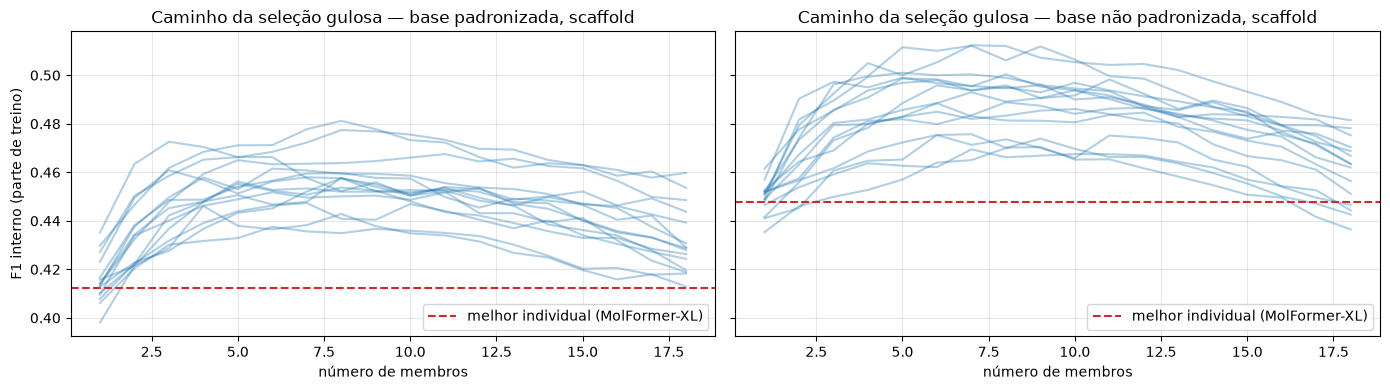

In [15]:
fig, axes = plt.subplots(1, len(BASES), figsize=(7 * len(BASES), 4), sharey=True)
for ax, base in zip(axes, BASES):
    cenario = (base, "scaffold")
    for (seed, k, nome), registro in ensembles[cenario].items():
        if nome == "Seleção gulosa":
            caminho = registro["caminho"]
            ax.plot(caminho["n_membros"], caminho["f1_interno"], color="tab:blue", alpha=0.35)
    f1_interno_melhor = np.mean([
        f1_score(Y[base][tr], (membros[cenario][(s, k, melhor_individual[base])]["inner_oof"]
                               >= U.LIMIAR_PADRAO).astype(int), zero_division=0)
        for (s, k), (tr, te) in indices[cenario].items()])
    ax.axhline(f1_interno_melhor, color="tab:red", ls="--", lw=1.5,
               label=f"melhor individual ({melhor_individual[base]})")
    ax.set_title(f"Caminho da seleção gulosa — {NOME_BASE[base]}, scaffold")
    ax.set_xlabel("número de membros")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
axes[0].set_ylabel("F1 interno (parte de treino)")
fig.tight_layout()
fig.savefig(out("ex033_caminho_guloso_scaffold.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Ranking

Modelos individuais, os três ensembles com todas as representações e os ensembles gulosos, ordenados pelo F1 médio de teste das 15 folds (limiar 0,5), em cada base e protocolo.

A coluna **posição** é entre os 25 modelos; **posição (22 do artigo)** é entre os 22 do EX_032, que é a que o artigo cita. Elas divergem para quem está abaixo de um dos três ensembles novos: o Graph-FP, por exemplo, é 15º entre os 22 e 16º entre os 25.

In [ ]:
media_todos = pd.concat([media_individuais, media_ensembles], ignore_index=True)

# Conjuntos de modelos das agregações entre modelos (seções 7, 8 e 11). O artigo cita os
# números de 22 modelos, que é o conjunto do EX_032; o de 25 inclui os três ensembles que o
# EX_033 acrescentou. Os dois são calculados em toda agregação, e o conjunto vai na saída.
TODOS_OS_MODELOS = sorted(media_todos["modelo"].unique())
MODELOS_22 = [m for m in TODOS_OS_MODELOS if m not in U.ENSEMBLES_NOVOS]
CONJUNTOS = {"22 (do artigo)": MODELOS_22, "25 (completo)": TODOS_OS_MODELOS}
agregados = []        # preenchido nas seções 8 e 11, salvo no fim da seção 11
for rotulo, modelos in CONJUNTOS.items():
    print(f"conjunto {rotulo}: {len(modelos)} modelos")
assert len(MODELOS_22) == 22 and len(TODOS_OS_MODELOS) == 25, "conjunto de modelos inesperado"

rankings = {}
for base, protocolo in CENARIOS:
    teste = media_todos.query("base == @base and protocolo == @protocolo and parte == 'teste'").set_index("modelo")
    ranking = pd.DataFrame({U.NOMES_METRICAS[m]: U.media_dp(teste[f"{m}_mean"], teste[f"{m}_std"])
                            for m in U.METRICAS})
    ranking["tipo"] = ["ensemble" if m in U.ENSEMBLES_033 else "individual" for m in ranking.index]
    ranking = ranking.loc[teste["f1_mean"].sort_values(ascending=False).index]
    ranking.insert(0, "posição", range(1, len(ranking) + 1))
    # Posição dentro dos 22 do artigo: é a que o texto cita (o Graph-FP, por exemplo, é 15º
    # entre os 22 e 16º entre os 25).
    nos_22 = [m for m in ranking.index if m in MODELOS_22]
    ranking.insert(1, "posição (22 do artigo)",
                   [nos_22.index(m) + 1 if m in MODELOS_22 else None for m in ranking.index])
    rankings[(base, protocolo)] = ranking
    ranking.to_csv(out(f"ex033_ranking_{base}_{protocolo}.csv"))
    print(f"Ranking por F1 de teste — {NOME_BASE[base]} — {NOME_PROTOCOLO[protocolo]} "
          f"(média ± desvio-padrão das 15 folds)")
    display(ranking)

## 8. Scaffold x aleatório

F1 e ROC-AUC de teste de cada modelo nos dois protocolos (média ± desvio-padrão das 15 folds), em cada base, e a diferença aleatório − scaffold. No split aleatório, compostos com o mesmo esqueleto caem em treino e teste, então o teste é mais parecido com o treino; a diferença mede quanto do desempenho depende de já ter visto esqueletos parecidos. As folds dos dois protocolos são diferentes, então a comparação é das médias, não fold a fold, e o desvio do Δ é √(dp_scaffold² + dp_aleatório²). O Δ médio entre modelos vem com o desvio-padrão entre os modelos.

A correlação de Spearman entre os F1 dos dois protocolos diz se a ordem dos modelos se mantém. O Δ médio e o Spearman são agregações entre modelos, então saem nos dois conjuntos (22 e 25); o artigo cita os de 22.

In [ ]:
comparacao_protocolos = {}
for base in BASES:
    tabela = U.comparar(media_todos.query("base == @base"), "protocolo", "scaffold", "aleatorio")
    tabela = tabela.sort_values("F1 (scaffold)", ascending=False)
    tabela.insert(0, "tipo", ["ensemble" if m in U.ENSEMBLES_033 else "individual" for m in tabela.index])
    comparacao_protocolos[base] = tabela
    tabela.to_csv(out(f"ex033_scaffold_x_aleatorio_{base}.csv"))
    print(f"{NOME_BASE[base]} — teste, média ± desvio-padrão das 15 folds")
    for rotulo, modelos in CONJUNTOS.items():
        sub = tabela.loc[[m for m in tabela.index if m in modelos]]
        rho = spearmanr(sub["F1 (scaffold)"], sub["F1 (aleatorio)"]).statistic
        delta_f1 = sub["Δ F1 (aleatorio − scaffold)"]
        delta_auc = sub["Δ ROC-AUC (aleatorio − scaffold)"]
        print(f"  [{len(sub)} modelos, conjunto {rotulo}] "
              f"Δ F1 médio entre modelos (aleatório − scaffold): {delta_f1.mean():+.4f} ± {delta_f1.std():.4f}; "
              f"Δ ROC-AUC médio: {delta_auc.mean():+.4f} ± {delta_auc.std():.4f}; "
              f"Spearman entre os F1: {rho:.3f}")
        agregados.append({"comparação": "aleatório − scaffold", "fixo": NOME_BASE[base],
                          "conjunto": rotulo, "modelos": len(sub),
                          "Δ F1 médio": delta_f1.mean(), "Δ F1 dp entre modelos": delta_f1.std(),
                          "Δ ROC-AUC médio": delta_auc.mean(),
                          "Δ ROC-AUC dp entre modelos": delta_auc.std(),
                          "modelos com Δ F1 < 0": int((delta_f1 < 0).sum()), "Spearman": rho})
    display(U.formatar_dp(tabela))

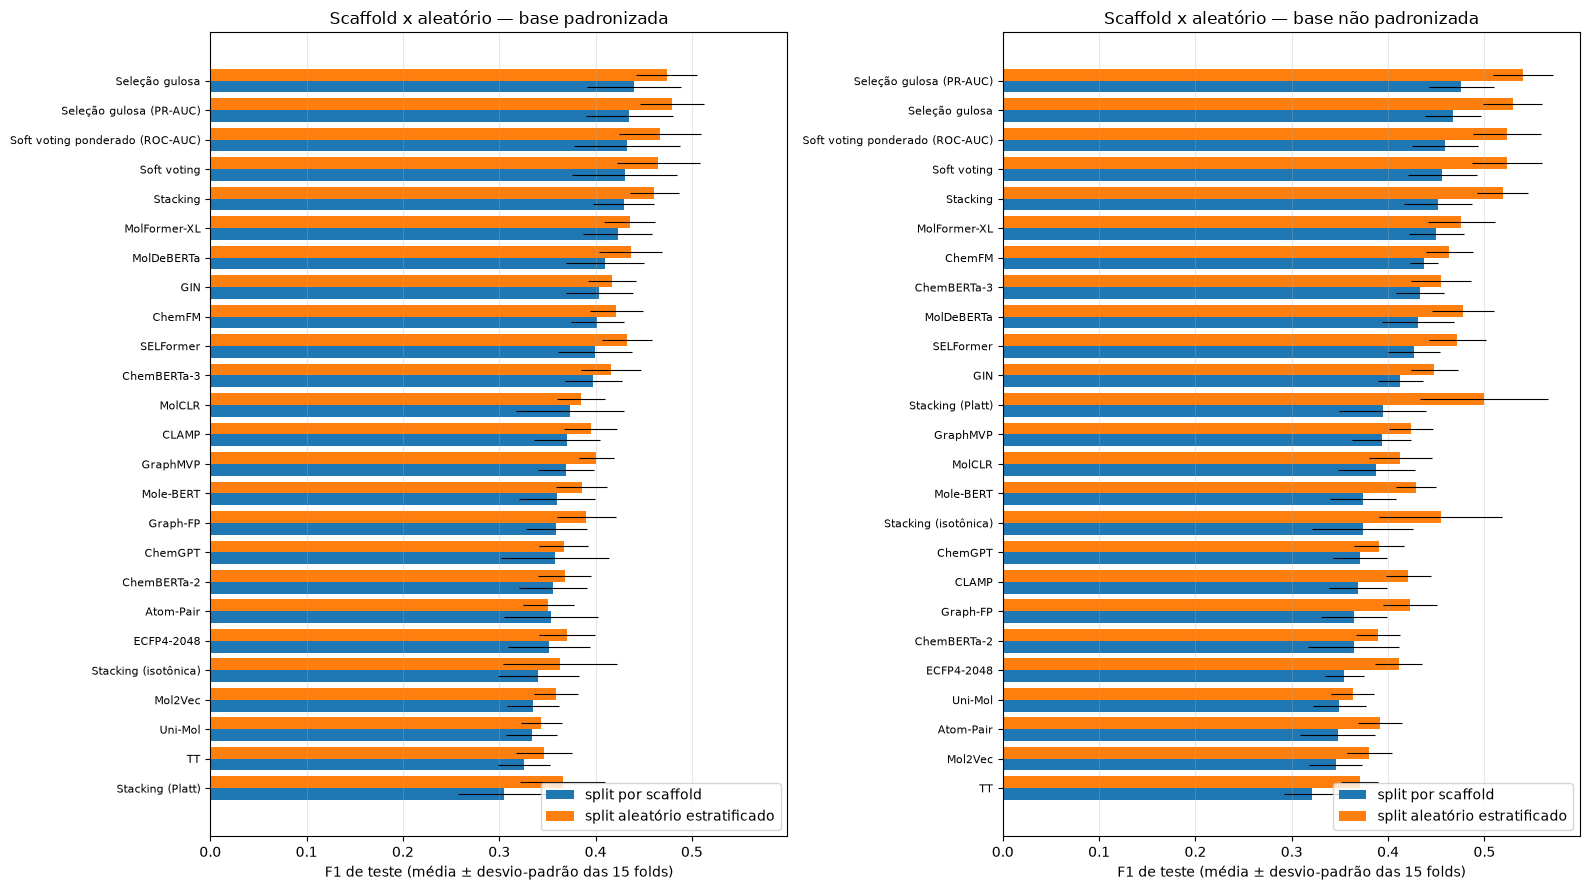

In [18]:
fig, axes = plt.subplots(1, len(BASES), figsize=(8 * len(BASES), 9), sharex=True)
for ax, base in zip(axes, BASES):
    teste = media_todos.query("base == @base and parte == 'teste'")
    ordem = comparacao_protocolos[base].index[::-1]
    posicoes = np.arange(len(ordem))
    for deslocamento, protocolo, cor in ((-0.2, "scaffold", "tab:blue"), (0.2, "aleatorio", "tab:orange")):
        valores = teste.query("protocolo == @protocolo").set_index("modelo").loc[ordem]
        ax.barh(posicoes + deslocamento, valores["f1_mean"], height=0.4, xerr=valores["f1_std"],
                color=cor, label=NOME_PROTOCOLO[protocolo], error_kw={"lw": 0.8})
    ax.set_yticks(posicoes)
    ax.set_yticklabels(ordem, fontsize=8)
    ax.set_xlabel("F1 de teste (média ± desvio-padrão das 15 folds)")
    ax.set_title(f"Scaffold x aleatório — {NOME_BASE[base]}")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(out("ex033_scaffold_x_aleatorio.png"), dpi=150, bbox_inches="tight")
plt.show()

## 9. Diversidade do ensemble guloso (split por scaffold)

Medidas par a par entre os membros de consenso do ensemble guloso no split por scaffold (escolhidos em pelo menos metade das folds), calculadas nas predições de teste da repetição de seed 42, no limiar 0,5 (cada composto é previsto uma vez, por um modelo que não o viu):

- **Double-fault:** fração de compostos que os dois erram (menor = mais complementares).
- **Q-statistic:** 0 = erros independentes, 1 = erros coincidentes.
- **Disagreement:** fração de compostos em que os dois discordam (maior = mais diversos).
- **Correlation coefficient:** correlação entre os vetores de acerto.

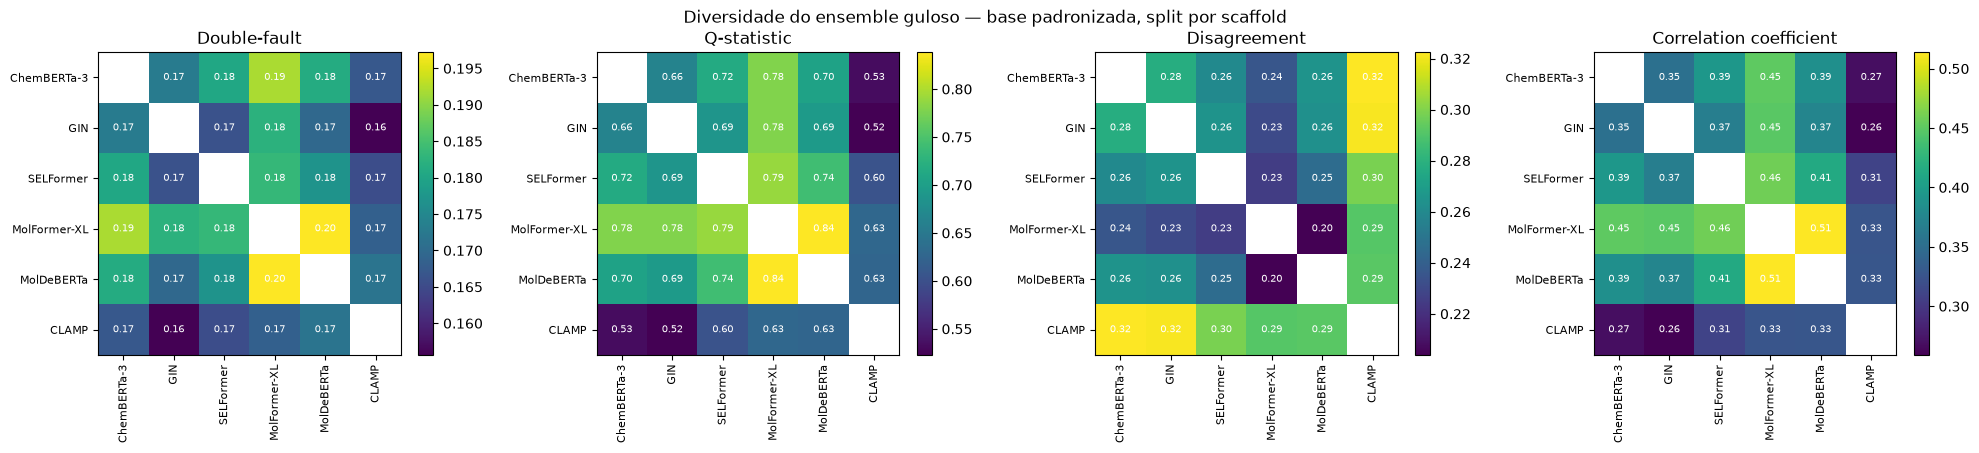

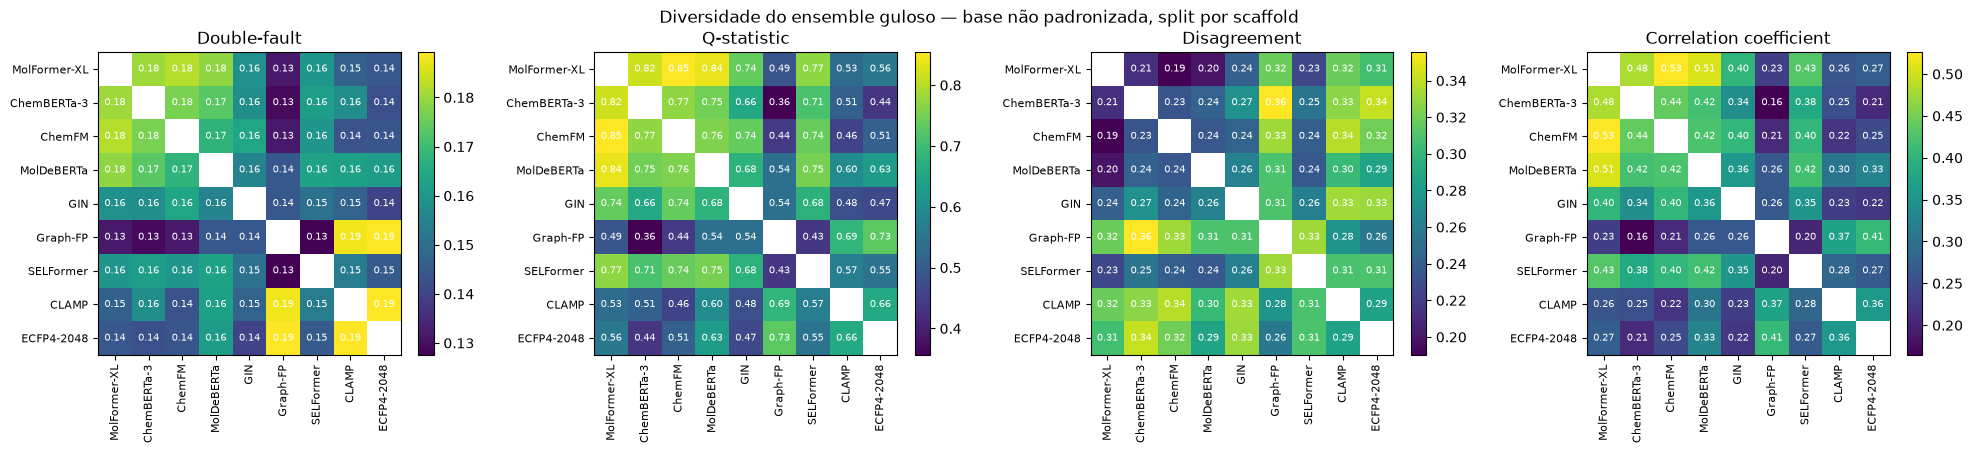

In [19]:
for base in BASES:
    cenario = (base, "scaffold")
    membros_div = consenso[base]
    if len(membros_div) < 2:
        print(f"{NOME_BASE[base]}: menos de 2 membros de consenso, sem mapa de diversidade.")
        continue
    acertos = U.acertos_oof(Y[base], indices[cenario], membros[cenario], membros_div, seed=SEEDS[0])
    fig, axes = plt.subplots(1, 4, figsize=(5 * 4, 4.4))
    for ax, (titulo, medida) in zip(axes, U.MEDIDAS_DIVERSIDADE.items()):
        matriz = U.pairwise_matrix(medida, acertos, membros_div)
        imagem = ax.imshow(matriz, cmap="viridis")
        ax.set_xticks(range(len(membros_div)))
        ax.set_xticklabels(membros_div, rotation=90, fontsize=8)
        ax.set_yticks(range(len(membros_div)))
        ax.set_yticklabels(membros_div, fontsize=8)
        for i in range(len(membros_div)):
            for j in range(len(membros_div)):
                if i != j:
                    ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
        ax.set_title(titulo)
        fig.colorbar(imagem, ax=ax, fraction=0.046)
    fig.suptitle(f"Diversidade do ensemble guloso — {NOME_BASE[base]}, split por scaffold")
    fig.tight_layout()
    fig.savefig(out(f"ex033_diversidade_{base}_scaffold.png"), dpi=150, bbox_inches="tight")
    plt.show()

## 10. Estudo do limiar (split por scaffold)

Até aqui todas as métricas usaram o limiar 0,5. Aqui o melhor modelo individual e o melhor ensemble **no split por scaffold** (maior F1 médio de teste) são avaliados na grade de limiares de 0,40 a 0,60 (passo 0,01), em cada base:

- **Curva OOF (linha cheia):** F1 médio das 15 folds nas probabilidades out-of-fold internas da parte de treino, em cada limiar.
- **Curva de teste (linha tracejada):** F1 médio das 15 folds no teste, em cada limiar. Só para visualização; não entra na escolha.
- **Limiar escolhido:** um por modelo, o pico da curva OOF.
- **Círculos:** as duas curvas em 0,5. **Estrelas:** as duas curvas no limiar escolhido.

A tabela traz exatamente os valores dos círculos e das estrelas, com o desvio-padrão das 15 folds. As folds são as mesmas nos dois limiares, então o desvio do Δ é o desvio da diferença fold a fold. O teste não entra na escolha, mas o OOF de uma fold vem de um treino que contém compostos de teste de outras folds. Como o limiar é um único escalar, esse vazamento é leve.

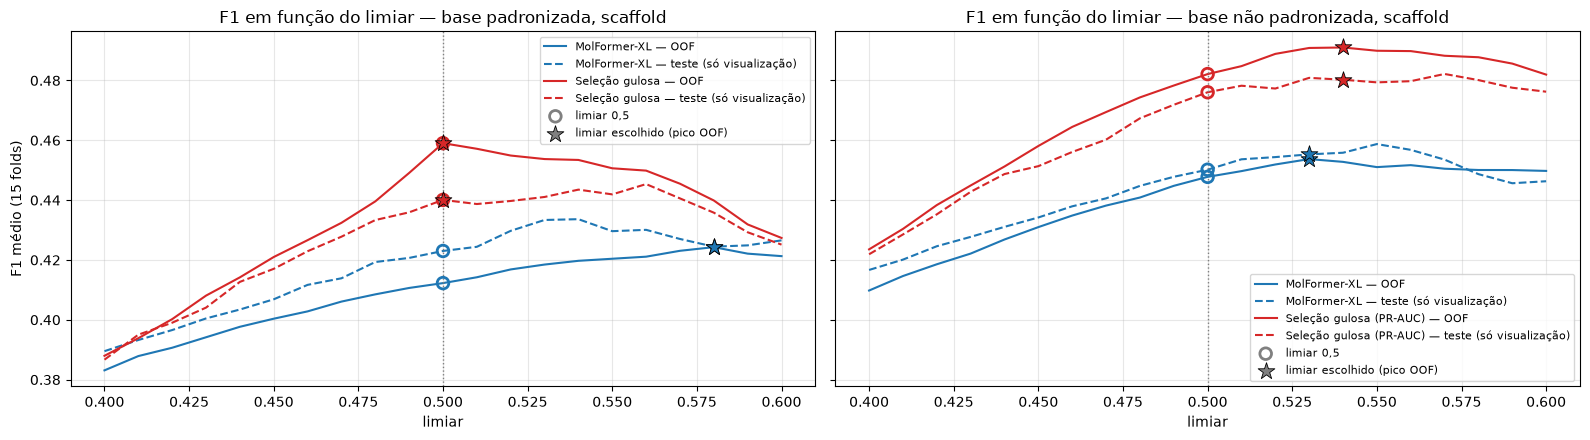

Média ± desvio-padrão das 15 folds


,base,modelo,limiar escolhido (pico OOF),"F1 OOF em 0,5",F1 OOF no limiar escolhido,Δ F1 OOF,"F1 teste em 0,5",F1 teste no limiar escolhido,Δ F1 teste
0,base padronizada,MolFormer-XL,0.58,0.4123 ± 0.0112,0.4243 ± 0.0136,0.0120 ± 0.0102,0.4230 ± 0.0356,0.4245 ± 0.0440,0.0014 ± 0.0229
1,base padronizada,Seleção gulosa,0.50,0.4590 ± 0.0113,0.4590 ± 0.0113,0.0000 ± 0.0000,0.4401 ± 0.0489,0.4401 ± 0.0489,0.0000 ± 0.0000
2,base não padronizada,MolFormer-XL,0.53,0.4478 ± 0.0069,0.4537 ± 0.0071,0.0059 ± 0.0042,0.4502 ± 0.0286,0.4553 ± 0.0332,0.0051 ± 0.0110
3,base não padronizada,Seleção gulosa (PR-AUC),0.54,0.4821 ± 0.0129,0.4910 ± 0.0109,0.0089 ± 0.0093,0.4761 ± 0.0341,0.4803 ± 0.0365,0.0042 ± 0.0165


In [20]:
resultados_limiar = []
fig, axes = plt.subplots(1, len(BASES), figsize=(8 * len(BASES), 4.5), sharey=True)
for ax, base in zip(axes, BASES):
    cenario = (base, "scaffold")
    teste = media_todos.query("base == @base and protocolo == 'scaffold' and parte == 'teste'")
    teste = teste.set_index("modelo")["f1_mean"]
    melhor_ensemble = teste[[m for m in U.ENSEMBLES_033 if m in teste.index]].idxmax()

    for modelo, cor in ((melhor_individual[base], "tab:blue"), (melhor_ensemble, "tab:red")):
        fonte = ensembles[cenario] if modelo in U.ENSEMBLES_033 else {
            (s, k, n): {**r, "inner_score": r["inner_oof"]} for (s, k, n), r in membros[cenario].items()}
        probas = {(s, k): r for (s, k, n), r in fonte.items() if n == modelo}
        por_fold, curva, limiar = U.estudo_limiar(Y[base], indices[cenario], probas)
        ax.plot(curva.index, curva["f1_oof_mean"], ls="-", color=cor, label=f"{modelo} — OOF")
        ax.plot(curva.index, curva["f1_teste_mean"], ls="--", color=cor,
                label=f"{modelo} — teste (só visualização)")
        ax.scatter([0.5, 0.5], curva.loc[0.5, ["f1_oof_mean", "f1_teste_mean"]], s=70,
                   facecolors="none", edgecolors=cor, linewidths=2, zorder=3)
        ax.scatter([limiar, limiar], curva.loc[limiar, ["f1_oof_mean", "f1_teste_mean"]], s=160,
                   marker="*", color=cor, edgecolors="black", linewidths=0.6, zorder=4)
        por_limiar = por_fold.set_index(["limiar", "seed", "fold"]).sort_index()
        linha = {"base": NOME_BASE[base], "modelo": modelo, "limiar escolhido (pico OOF)": limiar}
        for coluna, nome in (("f1_oof", "F1 OOF"), ("f1_teste", "F1 teste")):
            delta = por_limiar.loc[limiar, coluna] - por_limiar.loc[0.5, coluna]
            linha.update({
                f"{nome} em 0,5": curva.loc[0.5, f"{coluna}_mean"],
                f"{nome} em 0,5 dp": curva.loc[0.5, f"{coluna}_std"],
                f"{nome} no limiar escolhido": curva.loc[limiar, f"{coluna}_mean"],
                f"{nome} no limiar escolhido dp": curva.loc[limiar, f"{coluna}_std"],
                f"Δ {nome}": delta.mean(), f"Δ {nome} dp": delta.std()})
        resultados_limiar.append(linha)
    ax.axvline(0.5, color="gray", ls=":", lw=1)
    ax.scatter([], [], s=70, facecolors="none", edgecolors="gray", linewidths=2,
               label="limiar 0,5")
    ax.scatter([], [], s=160, marker="*", color="gray", edgecolors="black", linewidths=0.6,
               label="limiar escolhido (pico OOF)")
    ax.set_xlabel("limiar")
    ax.set_title(f"F1 em função do limiar — {NOME_BASE[base]}, scaffold")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("F1 médio (15 folds)")
fig.tight_layout()
fig.savefig(out("ex033_estudo_limiar_scaffold.png"), dpi=150, bbox_inches="tight")
plt.show()

tabela_limiar = pd.DataFrame(resultados_limiar)
tabela_limiar.to_csv(out("ex033_estudo_limiar_scaffold.csv"), index=False)
print("Média ± desvio-padrão das 15 folds")
display(U.formatar_dp(tabela_limiar))

## 11. Base padronizada x não padronizada

Primeiro, as oito métricas de teste de todos os modelos em cada base e protocolo (quatro tabelas, média ± desvio-padrão das 15 folds, ordenadas por F1). Depois, F1 e ROC-AUC de cada modelo nas duas bases, lado a lado, e a diferença padronizada − não padronizada. As bases não têm os mesmos compostos (a padronizada une as duplicatas estruturais), então a comparação é das médias, não composto a composto, e o desvio do Δ é √(dp_padronizada² + dp_original²). O Δ médio entre modelos vem com o desvio-padrão entre os modelos.

Como na seção 8, o Δ médio entre modelos e o Spearman saem nos dois conjuntos de modelos, e o artigo cita os de 22 — inclusive a contagem de quantos modelos pioram com a padronização, que é 19 de 22 (e 22 de 25).

Na base não padronizada, formas da mesma substância (sal e base livre, formas carregada e neutra, tautômeros) são linhas diferentes. No split aleatório elas podem cair uma no treino e outra no teste, e o modelo é avaliado em um composto que já viu. A tabela de vazamento conta esses casos nos dois protocolos; no split por scaffold ele quase não acontece, porque as formas da mesma substância quase sempre têm o mesmo esqueleto e ficam no mesmo grupo.

In [21]:
for base, protocolo in CENARIOS:
    print(f"Teste — {NOME_BASE[base]} — {NOME_PROTOCOLO[protocolo]} (média ± desvio-padrão das 15 folds)")
    display(rankings[(base, protocolo)])

Teste — base padronizada — split por scaffold (média ± desvio-padrão das 15 folds)


,posição,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC),tipo
modelo,,,,,,,,,,
Seleção gulosa,1,0.7440 ± 0.0362,0.5886 ± 0.0634,0.3535 ± 0.0494,0.4401 ± 0.0489,0.6822 ± 0.0381,0.3050 ± 0.0670,0.7499 ± 0.0462,0.4555 ± 0.0636,ensemble
Seleção gulosa (PR-AUC),2,0.7357 ± 0.0381,0.5955 ± 0.0624,0.3454 ± 0.0480,0.4352 ± 0.0453,0.6799 ± 0.0348,0.2984 ± 0.0623,0.7523 ± 0.0443,0.4614 ± 0.0589,ensemble
Soft voting ponderado (ROC-AUC),3,0.7432 ± 0.0437,0.5703 ± 0.0559,0.3514 ± 0.0578,0.4330 ± 0.0549,0.6745 ± 0.0412,0.2949 ± 0.0756,0.7427 ± 0.0513,0.4472 ± 0.0658,ensemble
Soft voting,4,0.7425 ± 0.0436,0.5661 ± 0.0558,0.3497 ± 0.0573,0.4304 ± 0.0545,0.6724 ± 0.0409,0.2916 ± 0.0751,0.7414 ± 0.0515,0.4457 ± 0.0653,ensemble
Stacking,5,0.7002 ± 0.0342,0.6604 ± 0.0485,0.3189 ± 0.0313,0.4290 ± 0.0318,0.6843 ± 0.0271,0.2909 ± 0.0455,0.7512 ± 0.0423,0.4531 ± 0.0632,ensemble
MolFormer-XL,6,0.7045 ± 0.0332,0.6357 ± 0.0565,0.3182 ± 0.0333,0.4230 ± 0.0356,0.6771 ± 0.0298,0.2819 ± 0.0497,0.7352 ± 0.0403,0.4283 ± 0.0647,individual
MolDeBERTa,7,0.6997 ± 0.0351,0.6127 ± 0.0619,0.3096 ± 0.0366,0.4102 ± 0.0404,0.6651 ± 0.0345,0.2634 ± 0.0572,0.7206 ± 0.0486,0.4077 ± 0.0620,individual
GIN,8,0.7023 ± 0.0238,0.5980 ± 0.0910,0.3068 ± 0.0227,0.4040 ± 0.0347,0.6608 ± 0.0329,0.2571 ± 0.0480,0.7157 ± 0.0366,0.4139 ± 0.0495,individual
ChemFM,9,0.7030 ± 0.0241,0.5891 ± 0.0722,0.3063 ± 0.0208,0.4018 ± 0.0278,0.6577 ± 0.0260,0.2530 ± 0.0386,0.7170 ± 0.0319,0.3994 ± 0.0418,individual


Teste — base padronizada — split aleatório estratificado (média ± desvio-padrão das 15 folds)


,posição,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC),tipo
modelo,,,,,,,,,,
Seleção gulosa (PR-AUC),1,0.7711 ± 0.0182,0.6206 ± 0.0482,0.3914 ± 0.0297,0.4795 ± 0.0329,0.7113 ± 0.0252,0.3578 ± 0.0428,0.7821 ± 0.0193,0.4906 ± 0.0387,ensemble
Seleção gulosa,2,0.7702 ± 0.0177,0.6096 ± 0.0516,0.3884 ± 0.0280,0.4738 ± 0.0317,0.7063 ± 0.0252,0.3506 ± 0.0416,0.7789 ± 0.0224,0.4831 ± 0.0447,ensemble
Soft voting ponderado (ROC-AUC),3,0.7696 ± 0.0207,0.5949 ± 0.0622,0.3854 ± 0.0363,0.4671 ± 0.0422,0.7001 ± 0.0324,0.3419 ± 0.0546,0.7748 ± 0.0213,0.4751 ± 0.0432,ensemble
Soft voting,4,0.7688 ± 0.0208,0.5923 ± 0.0630,0.3838 ± 0.0368,0.4651 ± 0.0431,0.6986 ± 0.0330,0.3393 ± 0.0556,0.7737 ± 0.0215,0.4730 ± 0.0433,ensemble
Stacking,5,0.7290 ± 0.0176,0.6823 ± 0.0454,0.3485 ± 0.0213,0.4610 ± 0.0257,0.7104 ± 0.0228,0.3357 ± 0.0361,0.7819 ± 0.0184,0.4891 ± 0.0390,ensemble
MolDeBERTa,6,0.7268 ± 0.0156,0.6237 ± 0.0537,0.3359 ± 0.0247,0.4365 ± 0.0328,0.6858 ± 0.0284,0.3003 ± 0.0452,0.7457 ± 0.0256,0.4320 ± 0.0439,individual
MolFormer-XL,7,0.7221 ± 0.0130,0.6316 ± 0.0478,0.3323 ± 0.0193,0.4354 ± 0.0268,0.6861 ± 0.0243,0.2990 ± 0.0377,0.7478 ± 0.0245,0.4370 ± 0.0436,individual
SELFormer,8,0.7232 ± 0.0145,0.6227 ± 0.0488,0.3320 ± 0.0192,0.4328 ± 0.0263,0.6832 ± 0.0235,0.2954 ± 0.0364,0.7419 ± 0.0224,0.4178 ± 0.0453,individual
ChemFM,9,0.7191 ± 0.0186,0.6028 ± 0.0438,0.3247 ± 0.0235,0.4216 ± 0.0274,0.6728 ± 0.0234,0.2796 ± 0.0382,0.7364 ± 0.0228,0.4196 ± 0.0365,individual


Teste — base não padronizada — split por scaffold (média ± desvio-padrão das 15 folds)


,posição,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC),tipo
modelo,,,,,,,,,,
Seleção gulosa (PR-AUC),1,0.7682 ± 0.0251,0.6117 ± 0.0550,0.3917 ± 0.0371,0.4761 ± 0.0341,0.7062 ± 0.0262,0.3518 ± 0.0457,0.7793 ± 0.0333,0.5026 ± 0.0411,ensemble
Seleção gulosa,2,0.7660 ± 0.0220,0.5979 ± 0.0565,0.3861 ± 0.0334,0.4676 ± 0.0293,0.6994 ± 0.0233,0.3410 ± 0.0393,0.7731 ± 0.0343,0.4954 ± 0.0438,ensemble
Soft voting ponderado (ROC-AUC),3,0.7642 ± 0.0271,0.5805 ± 0.0527,0.3823 ± 0.0413,0.4590 ± 0.0343,0.6914 ± 0.0251,0.3298 ± 0.0461,0.7678 ± 0.0379,0.4883 ± 0.0427,ensemble
Soft voting,4,0.7630 ± 0.0284,0.5768 ± 0.0517,0.3802 ± 0.0436,0.4563 ± 0.0358,0.6892 ± 0.0257,0.3261 ± 0.0481,0.7658 ± 0.0380,0.4848 ± 0.0427,ensemble
Stacking,5,0.7200 ± 0.0340,0.6694 ± 0.0536,0.3431 ± 0.0377,0.4522 ± 0.0352,0.7000 ± 0.0274,0.3207 ± 0.0484,0.7718 ± 0.0312,0.4922 ± 0.0456,ensemble
MolFormer-XL,6,0.7288 ± 0.0292,0.6437 ± 0.0395,0.3474 ± 0.0317,0.4502 ± 0.0286,0.6951 ± 0.0210,0.3168 ± 0.0386,0.7557 ± 0.0289,0.4462 ± 0.0419,individual
ChemFM,7,0.7236 ± 0.0241,0.6258 ± 0.0536,0.3381 ± 0.0187,0.4375 ± 0.0148,0.6848 ± 0.0139,0.3002 ± 0.0201,0.7501 ± 0.0148,0.4413 ± 0.0314,individual
ChemBERTa-3,8,0.7037 ± 0.0225,0.6589 ± 0.0472,0.3234 ± 0.0219,0.4333 ± 0.0249,0.6860 ± 0.0218,0.2946 ± 0.0350,0.7486 ± 0.0296,0.4319 ± 0.0500,individual
MolDeBERTa,9,0.7114 ± 0.0273,0.6360 ± 0.0641,0.3270 ± 0.0327,0.4311 ± 0.0378,0.6815 ± 0.0327,0.2909 ± 0.0531,0.7532 ± 0.0379,0.4465 ± 0.0580,individual


Teste — base não padronizada — split aleatório estratificado (média ± desvio-padrão das 15 folds)


,posição,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC),tipo
modelo,,,,,,,,,,
Seleção gulosa (PR-AUC),1,0.8060 ± 0.0130,0.6630 ± 0.0436,0.4556 ± 0.0265,0.5398 ± 0.0309,0.7493 ± 0.0234,0.4344 ± 0.0396,0.8257 ± 0.0241,0.5718 ± 0.0584,ensemble
Seleção gulosa,2,0.7992 ± 0.0142,0.6570 ± 0.0417,0.4433 ± 0.0277,0.5292 ± 0.0311,0.7429 ± 0.0231,0.4206 ± 0.0400,0.8221 ± 0.0260,0.5632 ± 0.0560,ensemble
Soft voting,3,0.7983 ± 0.0174,0.6447 ± 0.0456,0.4410 ± 0.0336,0.5234 ± 0.0363,0.7374 ± 0.0266,0.4131 ± 0.0470,0.8160 ± 0.0270,0.5500 ± 0.0566,ensemble
Soft voting ponderado (ROC-AUC),4,0.7984 ± 0.0166,0.6442 ± 0.0449,0.4411 ± 0.0322,0.5234 ± 0.0354,0.7373 ± 0.0260,0.4130 ± 0.0458,0.8172 ± 0.0269,0.5524 ± 0.0567,ensemble
Stacking,5,0.7657 ± 0.0145,0.7363 ± 0.0403,0.4011 ± 0.0218,0.5191 ± 0.0265,0.7540 ± 0.0222,0.4125 ± 0.0362,0.8243 ± 0.0255,0.5743 ± 0.0607,ensemble
Stacking (Platt),6,0.8618 ± 0.0149,0.4045 ± 0.0651,0.6577 ± 0.0633,0.4996 ± 0.0660,0.6806 ± 0.0340,0.4425 ± 0.0696,0.8243 ± 0.0255,0.5743 ± 0.0607,ensemble
MolDeBERTa,7,0.7495 ± 0.0139,0.6685 ± 0.0583,0.3721 ± 0.0232,0.4778 ± 0.0325,0.7174 ± 0.0283,0.3550 ± 0.0441,0.7862 ± 0.0266,0.4841 ± 0.0481,individual
MolFormer-XL,8,0.7494 ± 0.0171,0.6626 ± 0.0531,0.3715 ± 0.0272,0.4759 ± 0.0348,0.7150 ± 0.0295,0.3519 ± 0.0478,0.7825 ± 0.0239,0.4739 ± 0.0452,individual
SELFormer,9,0.7495 ± 0.0153,0.6516 ± 0.0460,0.3701 ± 0.0239,0.4718 ± 0.0298,0.7107 ± 0.0252,0.3461 ± 0.0409,0.7731 ± 0.0269,0.4732 ± 0.0478,individual


In [22]:
chaves = quimica_original["L5_inchikey"].to_numpy()
validas = pd.notna(chaves)
vazamento = []
for protocolo in PROTOCOLOS:
    for seed, k, tr, te in folds[("original", protocolo)]:
        no_treino = set(chaves[tr][validas[tr]])
        vazamento.append({"protocolo": NOME_PROTOCOLO[protocolo], "seed": seed, "fold": k,
                          "compostos de teste com a mesma substância no treino":
                              int(sum(c in no_treino for c in chaves[te][validas[te]])),
                          "compostos de teste": len(te)})
vazamento = pd.DataFrame(vazamento)
vazamento["fração"] = vazamento["compostos de teste com a mesma substância no treino"] / vazamento["compostos de teste"]
colunas = ["compostos de teste com a mesma substância no treino", "compostos de teste", "fração"]
resumo = vazamento.groupby("protocolo")[colunas].agg(["mean", "std"])
print("Vazamento de substâncias duplicadas na base não padronizada (média ± desvio-padrão das 15 folds)")
display(pd.DataFrame({c: U.media_dp(resumo[(c, "mean")], resumo[(c, "std")]) for c in colunas}))

Vazamento de substâncias duplicadas na base não padronizada (média ± desvio-padrão das 15 folds)


,compostos de teste com a mesma substância no treino,compostos de teste,fração
protocolo,,,
split aleatório estratificado,146.1333 ± 11.1539,846.6000 ± 0.5071,0.1726 ± 0.0132
split por scaffold,0.4000 ± 0.7368,846.6000 ± 1.4041,0.0005 ± 0.0009


In [ ]:
comparacao_bases = {}
for protocolo in PROTOCOLOS:
    tabela = U.comparar(media_todos.query("protocolo == @protocolo"), "base", "original", "padronizada")
    tabela = tabela.sort_values("F1 (padronizada)", ascending=False)
    tabela.insert(0, "tipo", ["ensemble" if m in U.ENSEMBLES_033 else "individual" for m in tabela.index])
    comparacao_bases[protocolo] = tabela
    tabela.to_csv(out(f"ex033_padronizada_x_original_{protocolo}.csv"))
    print(f"{NOME_PROTOCOLO[protocolo]} — teste, média ± desvio-padrão das 15 folds")
    for rotulo, modelos in CONJUNTOS.items():
        sub = tabela.loc[[m for m in tabela.index if m in modelos]]
        rho = spearmanr(sub["F1 (original)"], sub["F1 (padronizada)"]).statistic
        delta_f1 = sub["Δ F1 (padronizada − original)"]
        delta_auc = sub["Δ ROC-AUC (padronizada − original)"]
        print(f"  [{len(sub)} modelos, conjunto {rotulo}] "
              f"Δ F1 médio entre modelos (padronizada − original): {delta_f1.mean():+.4f} ± {delta_f1.std():.4f}; "
              f"Δ ROC-AUC médio: {delta_auc.mean():+.4f} ± {delta_auc.std():.4f}; "
              f"Spearman entre os F1: {rho:.3f}; "
              f"modelos que caem: {int((delta_f1 < 0).sum())}/{len(sub)}")
        agregados.append({"comparação": "padronizada − original", "fixo": NOME_PROTOCOLO[protocolo],
                          "conjunto": rotulo, "modelos": len(sub),
                          "Δ F1 médio": delta_f1.mean(), "Δ F1 dp entre modelos": delta_f1.std(),
                          "Δ ROC-AUC médio": delta_auc.mean(),
                          "Δ ROC-AUC dp entre modelos": delta_auc.std(),
                          "modelos com Δ F1 < 0": int((delta_f1 < 0).sum()), "Spearman": rho})
    display(U.formatar_dp(tabela))

# As quatro comparações nos dois conjuntos, na ordem em que o artigo as cita.
agregados = pd.DataFrame(agregados)
agregados.to_csv(out("ex033_agregados_por_conjunto.csv"), index=False)
print("
Agregações entre modelos nos dois conjuntos (o artigo cita as linhas de 22 modelos)")
display(agregados.round(4))

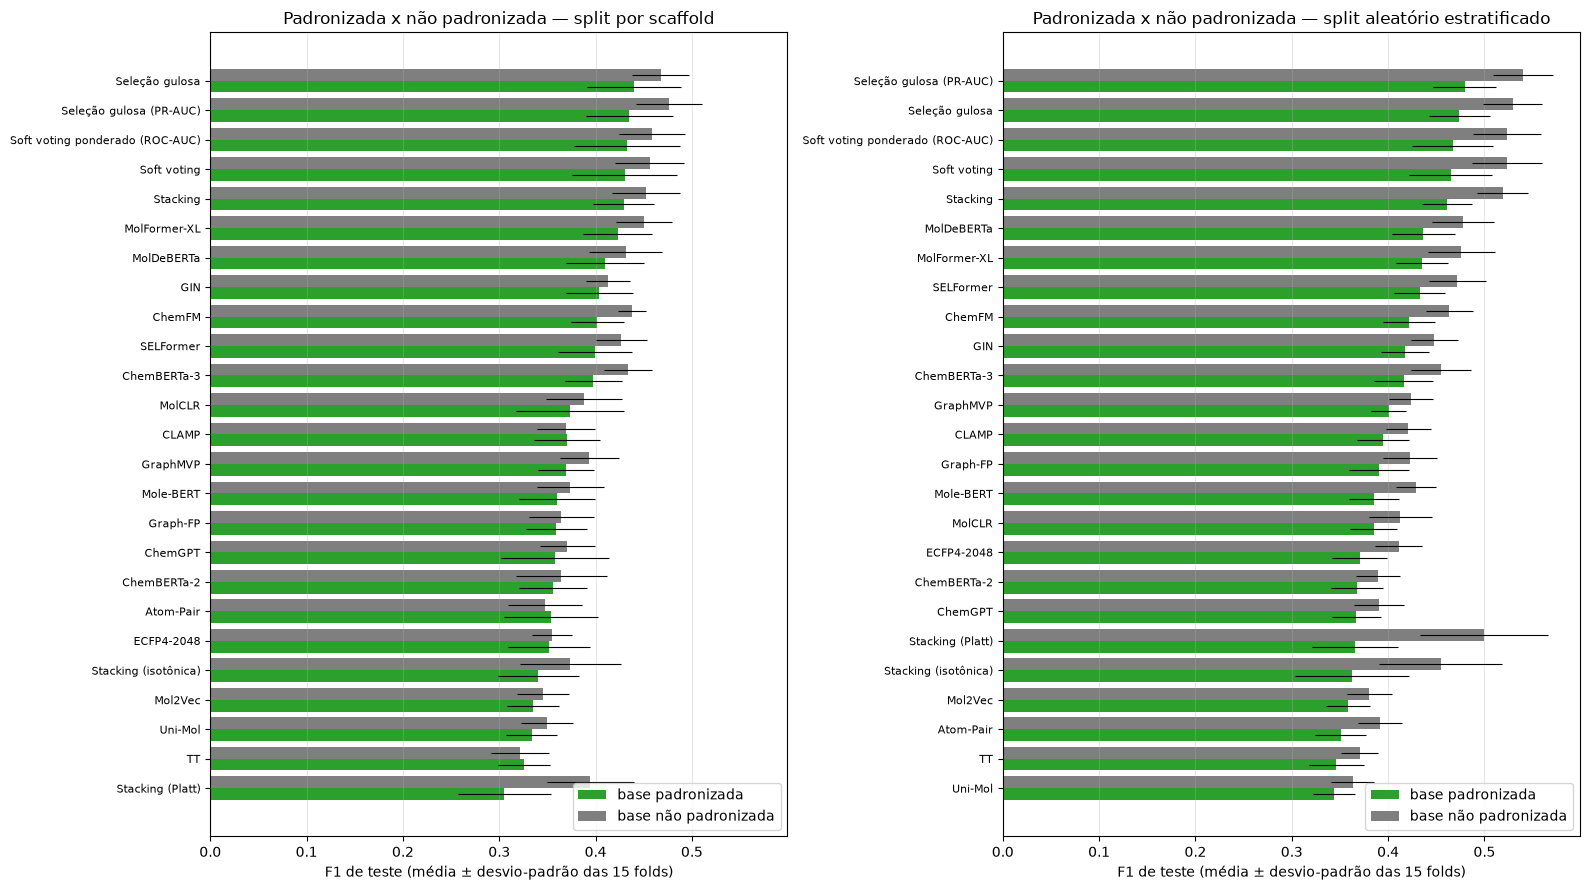

In [24]:
fig, axes = plt.subplots(1, len(PROTOCOLOS), figsize=(8 * len(PROTOCOLOS), 9), sharex=True)
for ax, protocolo in zip(axes, PROTOCOLOS):
    teste = media_todos.query("protocolo == @protocolo and parte == 'teste'")
    ordem = comparacao_bases[protocolo].index[::-1]
    posicoes = np.arange(len(ordem))
    for deslocamento, base, cor in ((-0.2, "padronizada", "tab:green"), (0.2, "original", "tab:gray")):
        valores = teste.query("base == @base").set_index("modelo").loc[ordem]
        ax.barh(posicoes + deslocamento, valores["f1_mean"], height=0.4, xerr=valores["f1_std"],
                color=cor, label=NOME_BASE[base], error_kw={"lw": 0.8})
    ax.set_yticks(posicoes)
    ax.set_yticklabels(ordem, fontsize=8)
    ax.set_xlabel("F1 de teste (média ± desvio-padrão das 15 folds)")
    ax.set_title(f"Padronizada x não padronizada — {NOME_PROTOCOLO[protocolo]}")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(out("ex033_padronizada_x_original.png"), dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# Resumo: melhor individual e melhor ensemble de cada cenário (F1 de teste, média ± desvio-padrão das 15 folds)
linhas = []
for base, protocolo in CENARIOS:
    teste = media_todos.query("base == @base and protocolo == @protocolo and parte == 'teste'").set_index("modelo")
    individual = teste.drop(U.ENSEMBLES_033, errors="ignore")["f1_mean"].idxmax()
    ensemble = teste.loc[[m for m in U.ENSEMBLES_033 if m in teste.index], "f1_mean"].idxmax()
    linhas.append({"base": NOME_BASE[base], "protocolo": NOME_PROTOCOLO[protocolo],
                   "melhor individual": individual,
                   "F1 do melhor individual": teste.loc[individual, "f1_mean"],
                   "F1 do melhor individual dp": teste.loc[individual, "f1_std"],
                   "melhor ensemble": ensemble,
                   "F1 do melhor ensemble": teste.loc[ensemble, "f1_mean"],
                   "F1 do melhor ensemble dp": teste.loc[ensemble, "f1_std"]})
resumo_cenarios = pd.DataFrame(linhas)
resumo_cenarios.to_csv(out("ex033_resumo_cenarios.csv"), index=False)
display(U.formatar_dp(resumo_cenarios))

,base,protocolo,melhor individual,F1 do melhor individual,melhor ensemble,F1 do melhor ensemble
0,base padronizada,split por scaffold,MolFormer-XL,0.4230 ± 0.0356,Seleção gulosa,0.4401 ± 0.0489
1,base padronizada,split aleatório estratificado,MolDeBERTa,0.4365 ± 0.0328,Seleção gulosa (PR-AUC),0.4795 ± 0.0329
2,base não padronizada,split por scaffold,MolFormer-XL,0.4502 ± 0.0286,Seleção gulosa (PR-AUC),0.4761 ± 0.0341
3,base não padronizada,split aleatório estratificado,MolDeBERTa,0.4778 ± 0.0325,Seleção gulosa (PR-AUC),0.5398 ± 0.0309


## 12. Validação externa

O conjunto externo (1.557 compostos, 35 positivos) não entra em nenhum treino nem em nenhuma escolha deste experimento. Ele é avaliado **uma vez**, sem k-fold, com modelos treinados com a base de treino inteira:

- **Modelos:** o melhor individual e o melhor ensemble do split por scaffold (maior F1 médio de teste), em cada base. Os modelos finais seguem a seção 3.1: `C`, membros da seleção gulosa, pesos e meta-modelo vêm de uma CV de 5 folds por scaffold sobre a base inteira. A base não padronizada ganha aqui os seus modelos finais, treinados do mesmo jeito.
- **Duas versões do externo:**
  - *não padronizada*: os SMILES originais, avaliados pelos modelos da base não padronizada, com os embeddings do EX_027;
  - *padronizada*: os SMILES passam pela mesma padronização da seção 1 (formas da mesma substância viram uma linha, rótulo positivo se qualquer forma for positiva), com embeddings gerados agora, e são avaliados pelos modelos da base padronizada.
- **Sobreposição removida:** compostos do externo que são a mesma substância (mesmo InChIKey padronizado) de algum composto de treino saem da avaliação, porque o modelo já os viu.
- **Cortes:** *completo* (tudo menos a sobreposição) e *scaffold inédito* (só compostos cujo esqueleto de Bemis–Murcko não aparece na base de treino).
- **Métricas de triagem**, livres de limiar: Precision@K e Recall@K para K = 50, 100 e 200, e BEDROC (α = 20). A prevalência do externo (≈ 2%) é muito menor que a do treino (17%), então essas métricas comparam a ordem dos compostos, não o corte em 0,5.

As predições ficam salvas em CSV. Rodar de novo carrega o arquivo e não lê o externo outra vez; cada leitura nova é registrada no log de leituras do conjunto externo (`resultados/json/external_read_log_ex026.json`). O EX_025, o EX_026 e o EX_027 já leram esse conjunto, então ele não é mais um lock-box virgem.

In [26]:
BASE_EXTERNA = os.path.join(ROOT, "dados", "Bases de dados", "Treinamento - limpas",
                            "Base_GeroLLM_reconstruida", "external_test_set.csv")
EXTERNA_PADRONIZADA = os.path.join(DIR_BASE, "externo_padronizado.csv")
DIR_EMBEDDINGS_EXTERNO = {
    "original": os.path.join(ROOT, "dados", "Embeddings_salvos", "Embeddings_GeroLLM_testeExterno"),
    "padronizada": os.path.join(ROOT, "dados", "Embeddings_salvos", "Embeddings_GeroLLM_testeExterno_padronizada"),
}
MODELOS_FINAIS_ORIGINAL = os.path.join(RESULTS_DIR, "modelos", "ex032_modelos_finais_original.joblib")
PREDICOES_EXTERNO = out("ex032_externo_predicoes.csv")   # mesma leitura do EX_032: os modelos finais não mudaram
LOG_EXTERNO = os.path.join(RESULTS_DIR, "json", "external_read_log_ex026.json")

# Versões do externo e a química de cada uma (InChIKey e grupo de scaffold)
externo = {"original": pd.read_csv(BASE_EXTERNA)}
if os.path.exists(EXTERNA_PADRONIZADA):
    externo["padronizada"] = pd.read_csv(EXTERNA_PADRONIZADA)
else:
    externo["padronizada"], _, _ = U.padronizar_base(externo["original"])
    externo["padronizada"].to_csv(EXTERNA_PADRONIZADA, index=False)
quimica_treino = {"original": quimica_original, "padronizada": quimica}
quimica_externo = {b: U.chemistry_table(externo[b]["smiles"].astype(str).tolist()) for b in BASES}

cortes = {b: U.external_cuts(quimica_treino[b], quimica_externo[b]) for b in BASES}
display(pd.DataFrame({NOME_BASE[b]: {
    "compostos no externo": len(externo[b]),
    "positivos no externo": int(externo[b]["label"].sum()),
    "mesma substância do treino (removidos)": cortes[b]["n_same_substance_removed"],
    "corte completo": int(cortes[b]["full"].sum()),
    "positivos no corte completo": int(externo[b]["label"].to_numpy()[cortes[b]["full"]].sum()),
    "corte scaffold inédito": int(cortes[b]["novel_scaffold"].sum()),
    "positivos no corte scaffold inédito": int(externo[b]["label"].to_numpy()[cortes[b]["novel_scaffold"]].sum()),
} for b in BASES}))

,base padronizada,base não padronizada
compostos no externo,1513,1557
positivos no externo,35,35
mesma substância do treino (removidos),456,481
corte completo,1057,1076
positivos no corte completo,32,32
corte scaffold inédito,426,430
positivos no corte scaffold inédito,14,14


In [27]:
# Modelos finais da base não padronizada (a padronizada já tem os seus, seção 3.1)
if os.path.exists(MODELOS_FINAIS_ORIGINAL):
    finais_original = joblib.load(MODELOS_FINAIS_ORIGINAL)
    print(f"[checkpoint] modelos finais carregados de {os.path.basename(MODELOS_FINAIS_ORIGINAL)}")
else:
    finais_original = U.treinar_finais(X["original"], Y["original"], NOMES, BINARIOS, C_GRID,
                                       GRUPOS["original"], n_jobs=N_JOBS)
    joblib.dump(finais_original, MODELOS_FINAIS_ORIGINAL)
modelos_finais = {"padronizada": finais, "original": finais_original}

# Melhor individual e melhor ensemble do split por scaffold, em cada base
avaliados = {}
for base in BASES:
    teste = media_todos.query("base == @base and protocolo == 'scaffold' and parte == 'teste'").set_index("modelo")["f1_mean"]
    avaliados[base] = [melhor_individual[base], teste[[m for m in U.ENSEMBLES if m in teste.index]].idxmax()]
    print(f"{NOME_BASE[base]}: {avaliados[base]}; membros da seleção gulosa final: "
          f"{modelos_finais[base]['membros_gulosos']}")

[checkpoint] modelos finais carregados de ex032_modelos_finais_original.joblib
base padronizada: ['MolFormer-XL', 'Seleção gulosa']; membros da seleção gulosa final: ['MolFormer-XL', 'ChemBERTa-3', 'Graph-FP', 'GIN', 'MolDeBERTa', 'CLAMP', 'ChemGPT']
base não padronizada: ['MolFormer-XL', 'Seleção gulosa']; membros da seleção gulosa final: ['MolFormer-XL', 'MolDeBERTa', 'SELFormer', 'CLAMP', 'GIN', 'Graph-FP', 'ChemBERTa-3']


In [28]:
# Embeddings do externo: só as representações que os modelos avaliados usam
necessarios = {b: sorted({n for m in avaliados[b] for n in U.encoders_do_modelo(modelos_finais[b], m)}) for b in BASES}


def arquivo_externo(base, chave):
    if base == "original" and chave == "ecfp4":      # nome do EX_027
        return os.path.join(DIR_EMBEDDINGS_EXTERNO[base], "fingerprints.npy")
    return os.path.join(DIR_EMBEDDINGS_EXTERNO[base], f"Embeddings_{chave}.npy")


def externo_pronto(base, nome):
    arquivo = arquivo_externo(base, ENCODERS[nome])
    return os.path.exists(arquivo) and np.load(arquivo, mmap_mode="r").shape[0] == len(externo[base])


faltando = [n for n in necessarios["padronizada"] if not externo_pronto("padronizada", n)]
if faltando:
    comando = [PYTHON_EMBEDDINGS, SCRIPT_EMBEDDINGS, "--csv", EXTERNA_PADRONIZADA, "--coluna", "smiles",
               "--rotulo", "label", "--saida", DIR_EMBEDDINGS_EXTERNO["padronizada"], "--encoders", *faltando]
    print("Gerando embeddings do externo padronizado:", ", ".join(faltando))
    processo = subprocess.Popen(comando, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linha in processo.stdout:
        if linha.startswith(("[ok]", "[erro]", "[checkpoint]", "Resumo")):
            print(linha, end="")
    processo.wait()

X_externo = {}
for base in BASES:
    ausentes = [n for n in necessarios[base] if not externo_pronto(base, n)]
    assert not ausentes, f"embeddings do externo faltando ({base}): {ausentes}"
    X_externo[base] = {n: np.load(arquivo_externo(base, ENCODERS[n])).astype(np.float32) for n in necessarios[base]}
    for n in necessarios[base]:        # embeddings na mesma ordem e com os mesmos rótulos do CSV
        pasta, nome_arquivo = os.path.split(arquivo_externo(base, ENCODERS[n]))
        nome_rotulos = ("rotulos_fingerprints.npy" if nome_arquivo == "fingerprints.npy"
                        else nome_arquivo.replace("Embeddings_", "rotulos_"))
        rotulos = np.load(os.path.join(pasta, nome_rotulos)).astype(int)
        assert (rotulos == externo[base]["label"].to_numpy()).all(), (base, n)
    print(f"{NOME_BASE[base]}: {len(necessarios[base])} representações do externo carregadas")

base padronizada: 7 representações do externo carregadas
base não padronizada: 7 representações do externo carregadas


In [29]:
# Leitura única do externo: as predições ficam salvas e não são refeitas
if os.path.exists(PREDICOES_EXTERNO):
    predicoes_externo = pd.read_csv(PREDICOES_EXTERNO)
    print(f"[checkpoint] predições do externo carregadas de {os.path.basename(PREDICOES_EXTERNO)} (sem nova leitura)")
else:
    partes = []
    for base in BASES:
        parte = pd.DataFrame({"base": base, "linha": np.arange(len(externo[base])),
                              "label": externo[base]["label"].astype(int).to_numpy(),
                              "corte_completo": cortes[base]["full"],
                              "corte_scaffold_inedito": cortes[base]["novel_scaffold"]})
        for modelo in avaliados[base]:
            parte[modelo] = U.prever_modelo(modelos_finais[base], X_externo[base], modelo)
        partes.append(parte)
    predicoes_externo = pd.concat(partes, ignore_index=True)
    predicoes_externo.to_csv(PREDICOES_EXTERNO, index=False)
    U.log_external_read(LOG_EXTERNO, "ex032-modelos-finais",
                        note="EX_032: melhor individual e melhor ensemble do split por scaffold, "
                             "modelos finais das bases padronizada e não padronizada; externo nas "
                             "versões padronizada e não padronizada; leitura única, métricas de triagem")

linhas = []
for base in BASES:
    parte = predicoes_externo.query("base == @base")
    for corte, coluna in (("completo", "corte_completo"), ("scaffold inédito", "corte_scaffold_inedito")):
        selecao = parte[parte[coluna]]
        for modelo in avaliados[base]:
            linhas.append({"externo": NOME_BASE[base].replace("base", "externo"), "corte": corte,
                           "modelo": modelo, **U.metricas_triagem(selecao["label"].to_numpy(), selecao[modelo].to_numpy())})
externo_triagem = pd.DataFrame(linhas)
externo_triagem.to_csv(out("ex033_externo_triagem.csv"), index=False)
print("Conjunto externo, leitura única (sem k-fold)")
display(externo_triagem.round(4))

[checkpoint] predições do externo carregadas de ex032_externo_predicoes.csv (sem nova leitura)
Conjunto externo, leitura única (sem k-fold)


,externo,corte,modelo,compostos,positivos,prevalência,Precision@50,Recall@50,Precision@100,Recall@100,Precision@200,Recall@200,BEDROC (α=20)
0,externo padronizada,completo,MolFormer-XL,1057,32,0.0303,0.20,0.3125,0.13,0.4062,0.080,0.5000,0.3056
1,externo padronizada,completo,Seleção gulosa,1057,32,0.0303,0.18,0.2812,0.15,0.4688,0.090,0.5625,0.3457
2,externo padronizada,scaffold inédito,MolFormer-XL,426,14,0.0329,0.08,0.2857,0.05,0.3571,0.035,0.5000,0.2538
3,externo padronizada,scaffold inédito,Seleção gulosa,426,14,0.0329,0.06,0.2143,0.06,0.4286,0.055,0.7857,0.2376
4,externo não padronizada,completo,MolFormer-XL,1076,32,0.0297,0.16,0.2500,0.12,0.3750,0.070,0.4375,0.2701
5,externo não padronizada,completo,Seleção gulosa,1076,32,0.0297,0.14,0.2188,0.11,0.3438,0.090,0.5625,0.2906
6,externo não padronizada,scaffold inédito,MolFormer-XL,430,14,0.0326,0.08,0.2857,0.05,0.3571,0.030,0.4286,0.2004
7,externo não padronizada,scaffold inédito,Seleção gulosa,430,14,0.0326,0.08,0.2857,0.04,0.2857,0.050,0.7143,0.2146


## 13. Intervalos de confiança e testes pareados (limitação i)

Até aqui tudo foi reportado como média ± desvio-padrão das 15 folds. Esse desvio descreve a **variabilidade entre partições**, não a incerteza da estimativa: as folds compartilham dados de treino e não são independentes, então ele não é intervalo de confiança e não sustenta afirmação de significância. Esta seção produz as duas peças que faltavam, com as funções do EX_027:

- **Bootstrap por scaffold.** Em uma repetição (seed 42), as 5 folds cobrem a base inteira e cada composto é previsto exatamente uma vez, por um modelo que não o viu. O bootstrap reamostra **grupos de scaffold inteiros**, não compostos: compostos do mesmo esqueleto não são observações independentes, e reamostrar linha a linha trata uma série congênere como vários sorteios independentes, o que estreita o intervalo sem informação nova. São 2.000 réplicas.
- **Bootstrap pareado.** Dois intervalos que se sobrepõem **não** implicam que a diferença seja nula, quando os modelos são correlacionados — e modelos avaliados nos mesmos compostos sempre são. A pergunta "A supera B" se responde no intervalo da diferença, com o mesmo reamostramento aplicado aos dois.
- **Teste t corrigido de Nadeau–Bengio.** Sobre as 15 folds, para as afirmações que só existem em forma de valores por fold. A correção troca o fator de variância 1/n por 1/n + n_teste/n_treino = 0,3167. O p ingênuo vai impresso ao lado, para mostrar o tamanho da diferença.

O cenário é o principal: **base padronizada, split por scaffold**. A referência é o melhor modelo individual.

In [30]:
N_BOOT = 2000
MODELOS_IC = U.ENSEMBLES_033 + [melhor_individual["padronizada"]]
cenario_ic = ("padronizada", "scaffold")

proba_oof = U.oof_de_uma_repeticao(
    Y["padronizada"], indices[cenario_ic],
    {**membros[cenario_ic], **ensembles[cenario_ic]}, MODELOS_IC, seed=42)

intervalos = U.tabela_intervalos(Y["padronizada"], proba_oof, GRUPOS["padronizada"],
                                 MODELOS_IC, n_boot=N_BOOT)
intervalos.to_csv(out("ex033_intervalos_scaffold_padronizada.csv"), index=False)
largo = intervalos.assign(
    valor=lambda d: d.apply(lambda r: f"{r['point']:.4f} [{r['ci_low']:.4f}, {r['ci_high']:.4f}]", axis=1)
).pivot(index="modelo", columns="metric", values="valor")
print(f"IC95% por bootstrap de scaffold ({N_BOOT} réplicas), base padronizada, scaffold, seed 42")
display(largo)

IC95% por bootstrap de scaffold (2000 réplicas), base padronizada, scaffold, seed 42


metric,average_precision,bedroc_20,f1,matthews_corrcoef,precision_at_100,roc_auc
modelo,,,,,,
MolFormer-XL,"0.4304 [0.3755, 0.4931]","0.5761 [0.5089, 0.6469]","0.4223 [0.3834, 0.4661]","0.2807 [0.2377, 0.3302]","0.7300 [0.6300, 0.8200]","0.7384 [0.7067, 0.7727]"
Seleção gulosa,"0.4521 [0.3998, 0.5134]","0.5962 [0.5345, 0.6627]","0.4370 [0.3935, 0.4880]","0.3008 [0.2493, 0.3598]","0.7600 [0.6500, 0.8600]","0.7484 [0.7170, 0.7807]"
Seleção gulosa (PR-AUC),"0.4606 [0.4118, 0.5134]","0.6081 [0.5511, 0.6660]","0.4392 [0.3973, 0.4849]","0.3036 [0.2565, 0.3547]","0.7900 [0.7000, 0.8702]","0.7541 [0.7253, 0.7842]"
Soft voting,"0.4366 [0.3868, 0.4919]","0.5767 [0.5176, 0.6367]","0.4265 [0.3826, 0.4762]","0.2870 [0.2369, 0.3437]","0.7200 [0.6300, 0.8000]","0.7424 [0.7103, 0.7755]"
Soft voting ponderado (ROC-AUC),"0.4391 [0.3894, 0.4952]","0.5802 [0.5213, 0.6403]","0.4276 [0.3836, 0.4769]","0.2884 [0.2393, 0.3459]","0.7300 [0.6300, 0.8100]","0.7436 [0.7116, 0.7769]"
Stacking,"0.4506 [0.3977, 0.5097]","0.5960 [0.5330, 0.6594]","0.4267 [0.3881, 0.4713]","0.2879 [0.2443, 0.3387]","0.7700 [0.6800, 0.8500]","0.7516 [0.7232, 0.7820]"
Stacking (Platt),"0.4483 [0.3959, 0.5065]","0.5930 [0.5298, 0.6565]","0.3164 [0.2706, 0.3649]","0.3037 [0.2605, 0.3510]","0.7700 [0.6800, 0.8400]","0.7515 [0.7230, 0.7820]"
Stacking (isotônica),"0.4353 [0.3835, 0.4934]","0.5980 [0.5225, 0.6485]","0.3393 [0.2894, 0.3884]","0.3025 [0.2566, 0.3497]","0.7200 [0.6200, 0.8000]","0.7491 [0.7192, 0.7812]"


In [31]:
# Cada ensemble contra o melhor individual, com o mesmo reamostramento nos dois
pareado = U.tabela_pareada(Y["padronizada"], proba_oof, GRUPOS["padronizada"],
                           U.ENSEMBLES_033, melhor_individual["padronizada"], n_boot=N_BOOT)
pareado.to_csv(out("ex033_pareado_scaffold_padronizada.csv"), index=False)
resumo = pareado.assign(
    valor=lambda d: d.apply(lambda r: f"{r['difference']:+.4f} [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]"
                                      + ("*" if r["excludes_zero"] else ""), axis=1)
).pivot(index="modelo", columns="metric", values="valor")
print(f"Ensemble − {melhor_individual['padronizada']}, bootstrap pareado por scaffold. "
      f"* = o intervalo exclui zero.")
display(resumo)

Ensemble − MolFormer-XL, bootstrap pareado por scaffold. * = o intervalo exclui zero.


metric,average_precision,bedroc_20,f1,matthews_corrcoef,roc_auc
modelo,,,,,
Seleção gulosa,"+0.0217 [-0.0057, +0.0475]","+0.0201 [-0.0190, +0.0569]","+0.0147 [-0.0030, +0.0371]","+0.0201 [-0.0045, +0.0501]","+0.0100 [-0.0031, +0.0234]"
Seleção gulosa (PR-AUC),"+0.0303 [+0.0037, +0.0520]*","+0.0320 [-0.0058, +0.0632]","+0.0169 [-0.0017, +0.0361]","+0.0229 [-0.0030, +0.0492]","+0.0157 [+0.0026, +0.0272]*"
Soft voting,"+0.0062 [-0.0180, +0.0308]","+0.0007 [-0.0336, +0.0340]","+0.0042 [-0.0151, +0.0271]","+0.0063 [-0.0203, +0.0371]","+0.0040 [-0.0095, +0.0187]"
Soft voting ponderado (ROC-AUC),"+0.0087 [-0.0155, +0.0331]","+0.0041 [-0.0303, +0.0371]","+0.0053 [-0.0139, +0.0275]","+0.0077 [-0.0188, +0.0378]","+0.0052 [-0.0081, +0.0195]"
Stacking,"+0.0202 [-0.0054, +0.0429]","+0.0199 [-0.0168, +0.0537]","+0.0044 [-0.0128, +0.0221]","+0.0071 [-0.0177, +0.0328]","+0.0132 [-0.0017, +0.0277]"
Stacking (Platt),"+0.0179 [-0.0082, +0.0403]","+0.0169 [-0.0197, +0.0506]","-0.1059 [-0.1541, -0.0630]*","+0.0230 [-0.0292, +0.0679]","+0.0131 [-0.0018, +0.0276]"
Stacking (isotônica),"+0.0049 [-0.0207, +0.0285]","+0.0219 [-0.0304, +0.0425]","-0.0830 [-0.1300, -0.0432]*","+0.0218 [-0.0264, +0.0617]","+0.0107 [-0.0050, +0.0255]"


In [32]:
# Nadeau-Bengio sobre as 15 folds, nos quatro cenários
por_fold = pd.concat([metricas_individuais, metricas_ensembles], ignore_index=True)
linhas = []
for base, protocolo in CENARIOS:
    parte = por_fold.query("base == @base and protocolo == @protocolo")
    tabela = U.tabela_nadeau_bengio(parte, U.ENSEMBLES_033, melhor_individual[base])
    linhas.append(tabela.assign(base=NOME_BASE[base], protocolo=NOME_PROTOCOLO[protocolo]))
nadeau = pd.concat(linhas, ignore_index=True)
nadeau.to_csv(out("ex033_nadeau_bengio.csv"), index=False)
print("Teste t corrigido de Nadeau-Bengio sobre as 15 folds (p ingênuo entre parênteses)")
display(nadeau.assign(
    p=lambda d: d.apply(lambda r: f"{r['p corrigido']:.3f} ({r['p ingênuo']:.3f})", axis=1)
).pivot_table(index=["base", "protocolo", "modelo"], columns="metrica", values="p", aggfunc="first"))

Teste t corrigido de Nadeau-Bengio sobre as 15 folds (p ingênuo entre parênteses)


<repositorio>/utils/regressao_logistica/ex033_utils.py:292: PerformanceWarning: indexing past lexsort depth may impact performance.
  a = tabela.loc[m, metrica].sort_index()
<repositorio>/utils/regressao_logistica/ex033_utils.py:293: PerformanceWarning: indexing past lexsort depth may impact performance.
  b = tabela.loc[referencia, metrica].sort_index()
<repositorio>/utils/regressao_logistica/ex033_utils.py:292: PerformanceWarning: indexing past lexsort depth may impact performance.
  a = tabela.loc[m, metrica].sort_index()
<repositorio>/utils/regressao_logistica/ex033_utils.py:292: PerformanceWarning: indexing past lexsort depth may impact performance.
  a = tabela.loc[m, metrica].sort_index()
<repositorio>/utils/regressao_logistica/ex033_utils.py:293: PerformanceWarning: indexing past lexsort depth may impact performance.
  b = tabela.loc[referencia, metrica].sort_index()
<repositorio>/utils/regressao_logistica/ex033_utils.py:292: PerformanceWarning: indexing past lexsort depth may 

metrica                                                                            average_precision  \
base                 protocolo                     modelo                                              
base não padronizada split aleatório estratificado Seleção gulosa                      0.000 (0.000)   
                                                   Seleção gulosa (PR-AUC)             0.001 (0.000)   
                                                   Soft voting                         0.005 (0.000)   
                                                   Soft voting ponderado (ROC-AUC)     0.004 (0.000)   
                                                   Stacking                            0.000 (0.000)   
                                                   Stacking (Platt)                    0.000 (0.000)   
                                                   Stacking (isotônica)                0.003 (0.000)   
                     split por scaffold            Seleção gulosa                      0.010 (0.000)   
                                                   Seleção gulosa (PR-AUC)             0.002 (0.000)   
                                                   Soft voting                         0.068 (0.001)   
                                                   Soft voting ponderado (ROC-AUC)     0.043 (0.000)   
                                                   Stacking                            0.010 (0.000)   
                                                   Stacking (Platt)                    0.010 (0.000)   
                                                   Stacking (isotônica)                0.198 (0.011)   
base padronizada     split aleatório estratificado Seleção gulosa                      0.032 (0.000)   
                                                   Seleção gulosa (PR-AUC)             0.026 (0.000)   
                                                   Soft voting                         0.052 (0.000)   
                                                   Soft voting ponderado (ROC-AUC)     0.042 (0.000)   
                                                   Stacking                            0.025 (0.000)   
                                                   Stacking (Platt)                    0.025 (0.000)   
                                                   Stacking (isotônica)                0.298 (0.033)   
                     split por scaffold            Seleção gulosa                      0.110 (0.002)   
                                                   Seleção gulosa (PR-AUC)             0.066 (0.001)   
                                                   Soft voting                         0.362 (0.059)   
                                                   Soft voting ponderado (ROC-AUC)     0.325 (0.043)   
                                                   Stacking                            0.108 (0.002)   
                                                   Stacking (Platt)                    0.108 (0.002)   
                                                   Stacking (isotônica)                0.741 (0.475)   

metrica                                                                                        f1  \
base                 protocolo                     modelo                                           
base não padronizada split aleatório estratificado Seleção gulosa                   0.000 (0.000)   
                                                   Seleção gulosa (PR-AUC)          0.000 (0.000)   
                                                   Soft voting                      0.001 (0.000)   
                                                   Soft voting ponderado (ROC-AUC)  0.001 (0.000)   
                                                   Stacking                         0.005 (0.000)   
                                                   Stacking (Platt)                 0.328 (0.044)   
                                                   Stacking (isotônica)

## 14. Calibração do stacking e seleção sem limiar (limitações vi e v)

### 14.1 O que a calibração muda

A calibração é monótona, então ROC-AUC e PR-AUC do stacking **não mudam**: a ordem dos compostos é a mesma. O que muda é onde o limiar 0,5 cai na distribuição de escores, e portanto todas as métricas que dependem do corte.

Aqui está o ponto que o diagnóstico do EX_032 não antecipou: **calibrar e continuar lendo o modelo em 0,5 piora o F1**, em vez de melhorar. O stacking descalibrado empurra as probabilidades para cima, então em 0,5 ele prevê positivo demais (recall alto, precision baixa). A calibração encolhe as probabilidades na direção da prevalência real, 17%; com isso quase nenhum composto passa de 0,5, o recall desaba e o F1 cai. As duas leituras são sintomas do mesmo problema: **0,5 não é o corte certo para esse modelo**, antes nem depois.

Por isso a seção avalia as duas coisas juntas. Para cada variante do stacking, o F1 é medido em 0,5 e no **limiar escolhido dentro do fold** — o que maximiza o F1 nas probabilidades out-of-fold internas da parte de treino, sobre uma grade larga de 0,05 a 0,95. A grade de 0,40 a 0,60 da seção 10 não serve aqui: o ótimo de um modelo calibrado fica muito abaixo dela. O teste do fold não entra na escolha.

A previsão a conferir na tabela: como a calibração é monótona, **os três stackings devem chegar ao mesmo F1 depois que o limiar é escolhido no fold**. Se isso acontecer, o diagnóstico "stacking descalibrado" se resolve em "stacking lido no limiar errado", e a calibração passa a valer pelo que ela de fato entrega — uma probabilidade interpretável e um limiar bem posto — e não por desempenho extra.

### 14.2 Seleção gulosa: F1 em 0,5 contra PR-AUC

A versão por F1 escolhe os membros maximizando o F1 no limiar 0,5, nas mesmas probabilidades out-of-fold que depois alimentam o estudo do limiar — por isso a curva OOF daquele ensemble tem um pico exatamente em 0,5 e o estudo não consegue avaliar outro limiar para ele. A versão por PR-AUC não usa limiar nenhum na escolha. Comparar as duas diz se a circularidade estava custando desempenho e se os membros escolhidos mudam.

In [33]:
cenario_ic = ("padronizada", "scaffold")
alvos = ["Stacking", "Stacking (isotônica)", "Stacking (Platt)",
         "Seleção gulosa", "Seleção gulosa (PR-AUC)"]
tabela = media_ensembles.query("base == 'padronizada' and protocolo == 'scaffold' and parte == 'teste'").set_index("modelo")
display(pd.DataFrame({U.NOMES_METRICAS[m]: U.media_dp(tabela.loc[alvos, f"{m}_mean"],
                                                      tabela.loc[alvos, f"{m}_std"])
                      for m in U.METRICAS}))

# Fração de compostos classificados como positivos no limiar 0,5: o sintoma da descalibração
linhas = []
for nome in alvos:
    fracoes = [( ensembles[cenario_ic][(s, k, nome)]["test_proba"] >= U.LIMIAR_PADRAO).mean()
               for (s, k) in indices[cenario_ic]]
    linhas.append({"modelo": nome, "fração prevista positiva (teste)": np.mean(fracoes),
                   "fração prevista positiva dp": np.std(fracoes, ddof=1)})
fracao = pd.DataFrame(linhas)
fracao.to_csv(out("ex033_calibracao_scaffold_padronizada.csv"), index=False)
print(f"Prevalência real: {Y['padronizada'].mean():.2%}")
display(U.formatar_dp(fracao))

,Accuracy,Recall,Precision,F1,Balanced accuracy,MCC,ROC-AUC,AP (PR-AUC)
modelo,,,,,,,,
Stacking,0.7002 ± 0.0342,0.6604 ± 0.0485,0.3189 ± 0.0313,0.4290 ± 0.0318,0.6843 ± 0.0271,0.2909 ± 0.0455,0.7512 ± 0.0423,0.4531 ± 0.0632
Stacking (isotônica),0.8416 ± 0.0113,0.2423 ± 0.0398,0.5973 ± 0.1031,0.3407 ± 0.0421,0.6032 ± 0.0181,0.3058 ± 0.0492,0.7483 ± 0.0411,0.4235 ± 0.0625
Stacking (Platt),0.8444 ± 0.0082,0.2025 ± 0.0381,0.6327 ± 0.0851,0.3053 ± 0.0485,0.5891 ± 0.0191,0.2945 ± 0.0531,0.7512 ± 0.0423,0.4531 ± 0.0632
Seleção gulosa,0.7440 ± 0.0362,0.5886 ± 0.0634,0.3535 ± 0.0494,0.4401 ± 0.0489,0.6822 ± 0.0381,0.3050 ± 0.0670,0.7499 ± 0.0462,0.4555 ± 0.0636
Seleção gulosa (PR-AUC),0.7357 ± 0.0381,0.5955 ± 0.0624,0.3454 ± 0.0480,0.4352 ± 0.0453,0.6799 ± 0.0348,0.2984 ± 0.0623,0.7523 ± 0.0443,0.4614 ± 0.0589


Prevalência real: 16.98%


,modelo,fração prevista positiva (teste)
0,Stacking,0.354300
1,Stacking (isotônica),0.070895
2,Stacking (Platt),0.054549
3,Seleção gulosa,0.286068
4,Seleção gulosa (PR-AUC),0.296734


In [34]:
# Limiar escolhido dentro do fold, grade larga: é isso que resolve a descalibração
por_fold_limiar = U.limiar_in_fold(Y["padronizada"], indices[cenario_ic],
                                   ensembles[cenario_ic], alvos)
por_fold_limiar.to_csv(out("ex033_limiar_in_fold_scaffold_padronizada.csv"), index=False)

agregado = por_fold_limiar.groupby("modelo").agg(["mean", "std"])
colunas = ["limiar escolhido"] + [f"{m}: {quando}" for m in ("f1", "precision", "recall")
                                  for quando in ("0,5", "limiar do fold")]
tabela = pd.DataFrame({c: U.media_dp(agregado[(c, "mean")], agregado[(c, "std")])
                       for c in colunas}).loc[alvos]
print("Limiar 0,5 contra o limiar escolhido no fold (média ± desvio-padrão das 15 folds)")
display(tabela)
print("Ganho de F1 ao escolher o limiar no fold:")
display((por_fold_limiar.assign(ganho=lambda d: d["f1: limiar do fold"] - d["f1: 0,5"])
         .groupby("modelo")["ganho"].agg(["mean", "std"]).loc[alvos].round(4)))

Limiar 0,5 contra o limiar escolhido no fold (média ± desvio-padrão das 15 folds)


,limiar escolhido,"f1: 0,5",f1: limiar do fold,"precision: 0,5",precision: limiar do fold,"recall: 0,5",recall: limiar do fold
modelo,,,,,,,
Stacking,0.6313 ± 0.0403,0.4290 ± 0.0318,0.4378 ± 0.0484,0.3189 ± 0.0313,0.4056 ± 0.0753,0.6604 ± 0.0485,0.4987 ± 0.0989
Stacking (isotônica),0.2213 ± 0.0130,0.3407 ± 0.0421,0.4407 ± 0.0510,0.5973 ± 0.1031,0.4109 ± 0.0737,0.2423 ± 0.0398,0.4956 ± 0.0941
Stacking (Platt),0.2780 ± 0.0471,0.3053 ± 0.0485,0.4363 ± 0.0467,0.6327 ± 0.0851,0.4011 ± 0.0718,0.2025 ± 0.0381,0.5024 ± 0.1017
Seleção gulosa,0.5133 ± 0.0168,0.4401 ± 0.0489,0.4393 ± 0.0475,0.3535 ± 0.0494,0.3679 ± 0.0498,0.5886 ± 0.0634,0.5572 ± 0.0859
Seleção gulosa (PR-AUC),0.5520 ± 0.0234,0.4352 ± 0.0453,0.4400 ± 0.0491,0.3454 ± 0.0480,0.4060 ± 0.0443,0.5955 ± 0.0624,0.4944 ± 0.1002


Ganho de F1 ao escolher o limiar no fold:


,mean,std
modelo,,
Stacking,0.0088,0.0325
Stacking (isotônica),0.1000,0.0517
Stacking (Platt),0.1310,0.0437
Seleção gulosa,-0.0008,0.0159
Seleção gulosa (PR-AUC),0.0048,0.0264


In [35]:
# Membros escolhidos por cada critério, nas 15 folds
for base in BASES:
    cenario = (base, "scaffold")
    freq = pd.concat({
        "F1 em 0,5": U.frequencia_selecao(ensembles[cenario], NOMES, "Seleção gulosa")["frequencia"],
        "PR-AUC": U.frequencia_selecao(ensembles[cenario], NOMES, "Seleção gulosa (PR-AUC)")["frequencia"],
    }, axis=1)
    freq.to_csv(out(f"ex033_frequencia_gulosa_criterio_{base}.csv"))
    tamanhos = {c: [len(r["membros"]) for (s, k, m), r in ensembles[cenario].items() if m == c]
                for c in ("Seleção gulosa", "Seleção gulosa (PR-AUC)")}
    print(f"{NOME_BASE[base]}, scaffold — tamanho mediano: "
          + "; ".join(f"{c} {np.median(v):.0f} (de {min(v)} a {max(v)})" for c, v in tamanhos.items()))
    display(freq.sort_values("PR-AUC", ascending=False).round(3))

base padronizada, scaffold — tamanho mediano: Seleção gulosa 7 (de 3 a 12); Seleção gulosa (PR-AUC) 6 (de 3 a 8)


,"F1 em 0,5",PR-AUC
GIN,0.800,1.000
MolFormer-XL,0.733,1.000
SELFormer,0.733,0.867
MolDeBERTa,0.733,0.733
ChemFM,0.400,0.733
ChemBERTa-3,0.933,0.533
CLAMP,0.600,0.467
ECFP4-2048,0.467,0.467
GraphMVP,0.200,0.067
ChemGPT,0.200,0.067


base não padronizada, scaffold — tamanho mediano: Seleção gulosa 7 (de 5 a 11); Seleção gulosa (PR-AUC) 7 (de 5 a 9)


,"F1 em 0,5",PR-AUC
MolDeBERTa,0.867,1.000
ChemFM,0.867,1.000
GIN,0.800,1.000
MolFormer-XL,0.867,0.933
ChemBERTa-3,0.867,0.867
SELFormer,0.667,0.867
CLAMP,0.667,0.867
ECFP4-2048,0.533,0.200
ChemBERTa-2,0.000,0.200
Graph-FP,0.733,0.133


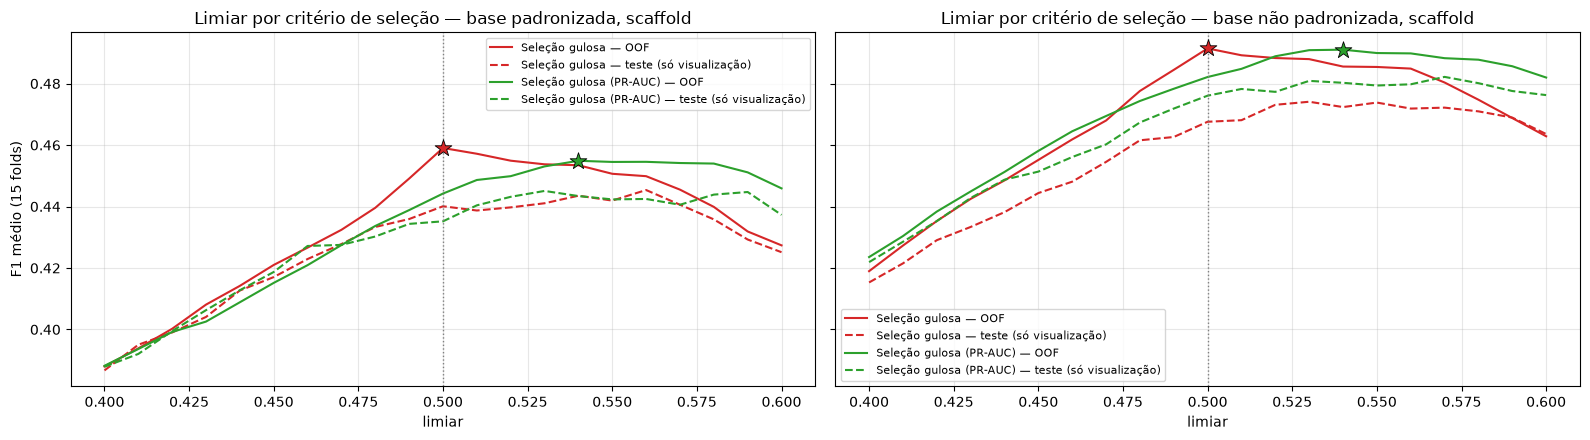

,base,critério,limiar escolhido (pico OOF),"F1 teste em 0,5",F1 teste no limiar escolhido
0,base padronizada,Seleção gulosa,0.50,0.4401,0.4401
1,base padronizada,Seleção gulosa (PR-AUC),0.54,0.4352,0.4434
2,base não padronizada,Seleção gulosa,0.50,0.4676,0.4676
3,base não padronizada,Seleção gulosa (PR-AUC),0.54,0.4761,0.4803


In [36]:
# O estudo do limiar refeito para a seleção gulosa por PR-AUC, que não tem o pico forçado em 0,5
linhas = []
fig, axes = plt.subplots(1, len(BASES), figsize=(8 * len(BASES), 4.5), sharey=True)
for ax, base in zip(axes, BASES):
    cenario = (base, "scaffold")
    for modelo, cor in (("Seleção gulosa", "tab:red"), ("Seleção gulosa (PR-AUC)", "tab:green")):
        probas = {(s, k): r for (s, k, n), r in ensembles[cenario].items() if n == modelo}
        curva, limiar = U.estudo_limiar(Y[base], indices[cenario], probas)[1:]
        ax.plot(curva.index, curva["f1_oof_mean"], ls="-", color=cor, label=f"{modelo} — OOF")
        ax.plot(curva.index, curva["f1_teste_mean"], ls="--", color=cor,
                label=f"{modelo} — teste (só visualização)")
        ax.scatter([limiar], [curva.loc[limiar, "f1_oof_mean"]], s=160, marker="*", color=cor,
                   edgecolors="black", linewidths=0.6, zorder=4)
        linhas.append({"base": NOME_BASE[base], "critério": modelo,
                       "limiar escolhido (pico OOF)": limiar,
                       "F1 teste em 0,5": curva.loc[0.5, "f1_teste_mean"],
                       "F1 teste no limiar escolhido": curva.loc[limiar, "f1_teste_mean"]})
    ax.axvline(0.5, color="gray", ls=":", lw=1)
    ax.set_xlabel("limiar")
    ax.set_title(f"Limiar por critério de seleção — {NOME_BASE[base]}, scaffold")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("F1 médio (15 folds)")
fig.tight_layout()
fig.savefig(out("ex033_limiar_por_criterio_scaffold.png"), dpi=150, bbox_inches="tight")
plt.show()

limiar_criterio = pd.DataFrame(linhas)
limiar_criterio.to_csv(out("ex033_limiar_por_criterio.csv"), index=False)
display(limiar_criterio.round(4))

## 15. Colapso por InChIKey (limitação iii)

No split por scaffold o vazamento de duplicatas já é quase zero (0,4 composto por fold), e mesmo assim a base padronizada perde cerca de 0,016 de F1 para a não padronizada. O EX_032 não isolou a causa. A hipótese mais plausível é **contagem**: na base não padronizada, uma substância presente em várias formas é pontuada várias vezes no mesmo fold de teste, e se essas substâncias forem as mais estudadas, e portanto mais fáceis, o F1 sobe sem que o modelo seja melhor.

O teste é direto e não exige reajustar nada: pegar as predições de teste da base **não padronizada** e agregá-las por InChIKey padronizado, com uma predição por substância (média das probabilidades) e o rótulo pela mesma regra "qualquer forma positiva" da padronização. Se o Δ para a base padronizada encolher, a queda era efeito de contagem. Se continuar, a causa é outra.

In [37]:
chaves_original = quimica_original["L5_inchikey"].to_numpy()
MODELOS_COLAPSO = U.ENSEMBLES_033 + [melhor_individual["original"], melhor_individual["padronizada"]]
MODELOS_COLAPSO = list(dict.fromkeys(MODELOS_COLAPSO))

linhas = []
for seed in SEEDS:
    proba_orig = U.oof_de_uma_repeticao(
        Y["original"], indices[("original", "scaffold")],
        {**membros[("original", "scaffold")], **ensembles[("original", "scaffold")]},
        MODELOS_COLAPSO, seed=seed)
    y_col, proba_col = U.colapsar_por_inchikey(Y["original"], proba_orig, chaves_original)
    proba_pad = U.oof_de_uma_repeticao(
        Y["padronizada"], indices[("padronizada", "scaffold")],
        {**membros[("padronizada", "scaffold")], **ensembles[("padronizada", "scaffold")]},
        MODELOS_COLAPSO, seed=seed)
    for modelo in MODELOS_COLAPSO:
        for cenario, y_c, p_c in (("não padronizada (linhas)", Y["original"], proba_orig[modelo]),
                                  ("não padronizada (colapsada)", y_col, proba_col[modelo]),
                                  ("padronizada", Y["padronizada"], proba_pad[modelo])):
            linhas.append({"seed": seed, "modelo": modelo, "avaliação": cenario,
                           "compostos": len(y_c), **U.metricas(y_c, p_c)})
colapso = pd.DataFrame(linhas)
colapso.to_csv(out("ex033_colapso_inchikey_por_seed.csv"), index=False)

resumo_colapso = colapso.groupby(["modelo", "avaliação"])[["compostos"] + U.METRICAS].agg(["mean", "std"])
tabela = pd.DataFrame({c: U.media_dp(resumo_colapso[(c, "mean")], resumo_colapso[(c, "std")])
                       for c in ["f1", "roc_auc", "average_precision"]})
tabela.columns = [U.NOMES_METRICAS[c] for c in ["f1", "roc_auc", "average_precision"]]
tabela.insert(0, "compostos", resumo_colapso[("compostos", "mean")].round(0).astype(int))
print("Predições OOF do split por scaffold, média ± desvio-padrão das 3 repetições")
display(tabela)

Predições OOF do split por scaffold, média ± desvio-padrão das 3 repetições


compostos  \
modelo                          avaliação                                
MolFormer-XL                    não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Seleção gulosa                  não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Seleção gulosa (PR-AUC)         não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Soft voting                     não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Soft voting ponderado (ROC-AUC) não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Stacking                        não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Stacking (Platt)                não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   
Stacking (isotônica)            não padronizada (colapsada)       3752   
                                não padronizada (linhas)          4233   
                                padronizada                       3752   

                                                                          F1  \
modelo                          avaliação                                      
MolFormer-XL                    não padronizada (colapsada)  0.4411 ± 0.0037   
                                não padronizada (linhas)     0.4491 ± 0.0032   
                                padronizada                  0.4222 ± 0.0009   
Seleção gulosa                  não padronizada (colapsada)  0.4611 ± 0.0064   
                                não padronizada (linhas)     0.4674 ± 0.0042   
                                padronizada                  0.4385 ± 0.0015   
Seleção gulosa (PR-AUC)         não padronizada (colapsada)  0.4715 ± 0.0115   
                                não padronizada (linhas)     0.4755 ± 0.0094   
                                padronizada                  0.4335 ± 0.0056   
Soft voting                     não padronizada (colapsada)  0.4532 ± 0.0028   
                                não padronizada (linhas)     0.4553 ± 0.0052   
                                padronizada                  0.4275 ± 0.0014   
Soft voting ponderado (ROC-AUC) não padronizada (colapsada)  0.4553 ± 0.0033   
                                não padronizada (linhas)     0.4582 ± 0.0038   
                                padronizada                  0.4300 ± 0.0022   
Stacking                        não padronizada (colapsada)  0.4459 ± 0.0153   
                                não padronizada (linhas)     0.4509 ± 0.0130   
                                padronizada                  0.4279 ± 0.0012   
Stacking (Platt)                não padronizada (colapsada)  0.3696 ± 0.0120   
                                não padronizada (linhas)     0.3970 ± 0.0100   
                                padronizada                  0.3065 ± 0.0088   
Stacking (isotônica)            não padronizada (colapsada)  0.3582 ± 0.0066   
                                não padronizada (linhas)     0.3760 ± 0.0091   
                                padronizada                  0.3417 ± 0.0081   

                                                       

In [38]:
# O Δ padronizada − não padronizada, antes e depois do colapso
largo = colapso.pivot_table(index=["modelo", "seed"], columns="avaliação", values="f1")
deltas = pd.DataFrame({
    "Δ F1 (padronizada − linhas)": largo["padronizada"] - largo["não padronizada (linhas)"],
    "Δ F1 (padronizada − colapsada)": largo["padronizada"] - largo["não padronizada (colapsada)"],
}).groupby("modelo").agg(["mean", "std"])
tabela = pd.DataFrame({c: U.media_dp(deltas[(c, "mean")], deltas[(c, "std")])
                       for c in ["Δ F1 (padronizada − linhas)", "Δ F1 (padronizada − colapsada)"]})
tabela.to_csv(out("ex033_colapso_inchikey_delta.csv"))
print("Se a segunda coluna estiver perto de zero, a queda da padronização era efeito de contagem.")
display(tabela)

Se a segunda coluna estiver perto de zero, a queda da padronização era efeito de contagem.


,Δ F1 (padronizada − linhas),Δ F1 (padronizada − colapsada)
modelo,,
MolFormer-XL,-0.0270 ± 0.0039,-0.0189 ± 0.0046
Seleção gulosa,-0.0289 ± 0.0048,-0.0225 ± 0.0070
Seleção gulosa (PR-AUC),-0.0420 ± 0.0123,-0.0380 ± 0.0147
Soft voting,-0.0278 ± 0.0039,-0.0257 ± 0.0014
Soft voting ponderado (ROC-AUC),-0.0282 ± 0.0041,-0.0253 ± 0.0052
Stacking,-0.0231 ± 0.0127,-0.0181 ± 0.0147
Stacking (Platt),-0.0905 ± 0.0096,-0.0631 ± 0.0160
Stacking (isotônica),-0.0343 ± 0.0067,-0.0165 ± 0.0016


## 16. Ablação dos conflitos de rótulo (limitação iv)

A fusão por InChIKey junta formas da mesma substância que vinham com rótulos diferentes. São **82 substâncias**, todas resolvidas como positivas pela mesma regra que a base já usava para conflitos entre fontes. Essa escolha nunca foi testada na base padronizada. Aqui as três políticas são comparadas:

| Política | Compostos | Positivos | Prevalência |
|---|---|---|---|
| positivo (padrão do EX_032) | 3.752 | 637 | 16,98% |
| removido | 3.670 | 555 | 15,12% |
| negativo | 3.752 | 555 | 14,79% |

Diferente das outras seções, esta **reajusta os modelos**: mudar rótulos invalida os checkpoints. Para manter o custo em cerca de uma hora, a ablação roda só na base padronizada e só no split por scaffold, que é o cenário principal; são 2 políticas novas × 18 representações × 15 folds = 540 ajustes, em checkpoints próprios. A ablação não existe para a base não padronizada, onde essas formas são linhas separadas com seus próprios rótulos e não há conflito a resolver.

O que interessa não é o valor absoluto, que muda só pela prevalência, mas se **a ordem das representações e a vantagem do ensemble sobrevivem** à política de rótulo.

In [39]:
checkpoints_ablacao = U.Checkpoints(os.path.join(RESULTS_DIR, "checkpoints", "checkpoints_ex033_ablacao"))
ablacao = {}
for politica in U.POLITICAS_CONFLITO:
    base_pol, mantidas = U.aplicar_politica_conflito(padronizada, politica)
    y_pol = base_pol["label"].astype(int).to_numpy()
    grupos_pol = GRUPOS["padronizada"][mantidas]
    X_pol = {n: X["padronizada"][n][mantidas] for n in NOMES}
    folds_pol = U.repeated_scaffold_folds(y_pol, grupos_pol, n_splits=N_SPLITS, seeds=SEEDS)
    indices_pol = {(s, k): (tr, te) for s, k, tr, te in folds_pol}
    print(f"[{politica}] {len(y_pol)} compostos, {y_pol.sum()} positivos ({y_pol.mean():.2%})")
    # A política "positivo" é a do EX_032: mesmos rótulos, mesmas folds, mesmos checkpoints.
    # Só as outras duas precisam de ajustes novos (2 x 18 x 15 = 540).
    reaproveita = politica == "positivo"
    membros_pol = U.rodar_membros(
        X_pol, y_pol, folds_pol, NOMES, BINARIOS, C_GRID,
        checkpoints if reaproveita else checkpoints_ablacao, "scaffold", grupos=grupos_pol,
        n_jobs=N_JOBS, prefixo="padronizada_scaffold" if reaproveita else f"ablacao_{politica}")
    ensembles_pol = {}
    for (seed, k), (tr, te) in indices_pol.items():
        registros = {n: membros_pol[(seed, k, n)] for n in NOMES}
        for nome, registro in U.ensembles_do_fold(y_pol, tr, registros, NOMES, seed).items():
            ensembles_pol[(seed, k, nome)] = registro
    ablacao[politica] = {"y": y_pol, "indices": indices_pol,
                         "metricas": pd.concat([
                             U.tabela_metricas(y_pol, indices_pol, membros_pol, "scaffold", politica),
                             U.tabela_metricas(y_pol, indices_pol, ensembles_pol, "scaffold", politica)],
                             ignore_index=True)}

metricas_ablacao = pd.concat([ablacao[p]["metricas"] for p in U.POLITICAS_CONFLITO], ignore_index=True)
metricas_ablacao.to_csv(out("ex033_ablacao_conflitos_por_fold.csv"), index=False)
media_ablacao = U.media_por_modelo(metricas_ablacao)
media_ablacao.to_csv(out("ex033_ablacao_conflitos_media.csv"), index=False)

[positivo] 3752 compostos, 637 positivos (16.98%)
[removido] 3670 compostos, 555 positivos (15.12%)
[negativo] 3752 compostos, 555 positivos (14.79%)


In [ ]:
# A ordem das representações muda com a política?
teste_ablacao = media_ablacao.query("parte == 'teste'")
ordens = {p: teste_ablacao.query("base == @p").set_index("modelo")["f1_mean"] for p in U.POLITICAS_CONFLITO}
linhas = []
for metrica in ("f1", "roc_auc", "average_precision"):
    valores = {p: teste_ablacao.query("base == @p").set_index("modelo")[f"{metrica}_mean"]
               for p in U.POLITICAS_CONFLITO}
    comum = sorted(set.intersection(*(set(v.index) for v in valores.values())))
    for a, b in (("positivo", "removido"), ("positivo", "negativo")):
        rho = spearmanr(valores[a].loc[comum], valores[b].loc[comum]).statistic
        linhas.append({"métrica": U.NOMES_METRICAS[metrica], "comparação": f"{a} x {b}",
                       "Spearman": rho})
spearman_ablacao = pd.DataFrame(linhas).pivot(index="métrica", columns="comparação", values="Spearman")
spearman_ablacao.to_csv(out("ex033_ablacao_spearman.csv"))
print(f"Correlação de Spearman entre os rankings dos {len(comum)} modelos sob cada política")
display(spearman_ablacao.round(3))

In [41]:
# A vantagem do ensemble sobrevive a cada política?
linhas = []
for politica in U.POLITICAS_CONFLITO:
    t = teste_ablacao.query("base == @politica").set_index("modelo")
    individuais = t.drop(U.ENSEMBLES_033, errors="ignore")
    melhor_ind = individuais["f1_mean"].idxmax()
    for metrica in ("f1", "roc_auc", "average_precision", "mcc"):
        melhor_ens = t.loc[[m for m in U.ENSEMBLES_033 if m in t.index], f"{metrica}_mean"].idxmax()
        linhas.append({"política": politica, "métrica": U.NOMES_METRICAS[metrica],
                       "melhor individual": melhor_ind,
                       "melhor ensemble": melhor_ens,
                       "Δ (ensemble − individual)": t.loc[melhor_ens, f"{metrica}_mean"]
                                                    - individuais[f"{metrica}_mean"].max()})
ganho_ablacao = pd.DataFrame(linhas)
ganho_ablacao.to_csv(out("ex033_ablacao_ganho_ensemble.csv"), index=False)
print("Se o Δ for positivo nas três políticas, a vantagem do ensemble não depende da regra de rótulo.")
display(ganho_ablacao.pivot(index="política", columns="métrica", values="Δ (ensemble − individual)").round(4))
display(ganho_ablacao)

Se o Δ for positivo nas três políticas, a vantagem do ensemble não depende da regra de rótulo.


métrica,AP (PR-AUC),F1,MCC,ROC-AUC
política,,,,
negativo,0.0366,0.0175,0.0540,0.0170
positivo,0.0331,0.0171,0.0239,0.0172
removido,0.0365,0.0234,0.0302,0.0207


,política,métrica,melhor individual,melhor ensemble,Δ (ensemble − individual)
0,positivo,F1,MolFormer-XL,Seleção gulosa,0.017070
1,positivo,ROC-AUC,MolFormer-XL,Seleção gulosa (PR-AUC),0.017168
2,positivo,AP (PR-AUC),MolFormer-XL,Seleção gulosa (PR-AUC),0.033101
3,positivo,MCC,MolFormer-XL,Stacking (isotônica),0.023884
4,removido,F1,MolFormer-XL,Seleção gulosa (PR-AUC),0.023379
5,removido,ROC-AUC,MolFormer-XL,Stacking,0.020713
6,removido,AP (PR-AUC),MolFormer-XL,Seleção gulosa (PR-AUC),0.036517
7,removido,MCC,MolFormer-XL,Seleção gulosa (PR-AUC),0.030193
8,negativo,F1,MolFormer-XL,Seleção gulosa,0.017471
9,negativo,ROC-AUC,MolFormer-XL,Stacking,0.016989
